In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr, spearmanr
from typing import Literal
import re

In [30]:
df = pd.read_csv("../generated_data/loss_aversion_results_cleaned.csv")
# df = df.drop(columns=["Loss_Aversion_12"]) # Drop this item as the prompt was wrong and the results are not meaningful
used_items = [
    "Loss_Aversion_1",
    "Loss_Aversion_2",
    "Loss_Aversion_3",
    "Loss_Aversion_4",
    "Loss_Aversion_7",
    "Loss_Aversion_8",
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13",
    "Loss_Aversion_13_inverse",
    "Loss_Aversion_14",
    "Loss_Aversion_14_inverse"
]

df = df[used_items + ["llm", "persona", "thinking", "experiment_group"]].copy()

In [31]:
prefix = "Loss_Aversion"
invalid_counts = {}

for i in range(1, 15):
    for suffix in ["", "_inverse"]:
        col = f"{prefix}_{i}{suffix}"

        if col not in df.columns:
            continue

        invalid_mask = ~df[col].isin(["A", "B"])
        invalid = df.loc[invalid_mask, [ "llm", col]]

        if not invalid.empty:
            print(col)
            print(invalid)
            print("--------------------")
        counts = df.loc[invalid_mask, "llm"].value_counts()

        for llm, count in counts.items():
                    invalid_counts[llm] = invalid_counts.get(llm, 0) + count

print(pd.Series(invalid_counts, name="total_invalid_responses").sort_values(ascending=False))

Loss_Aversion_1
                  llm                                    Loss_Aversion_1
2664  deepseek-v4-pro  I'm in. Just give me the choice and I'll answe...
--------------------
Loss_Aversion_3
                  llm Loss_Aversion_3
61    deepseek-v4-pro              .B
1378  deepseek-v4-pro             NaN
--------------------
Loss_Aversion_4
                    llm                Loss_Aversion_4
458   deepseek-v4-flash   with exactly one letter: A.A
2792  deepseek-v4-flash                            NaN
--------------------
Loss_Aversion_7
                    llm         Loss_Aversion_7
952   deepseek-v4-flash                     NaN
2518    deepseek-v4-pro   with no explanation.B
--------------------
Loss_Aversion_13
                   llm Loss_Aversion_13
957  deepseek-v4-flash                A
--------------------
Loss_Aversion_13_inverse
                  llm Loss_Aversion_13_inverse
1207  deepseek-v4-pro               I choose A
--------------------
Loss_Aversion_14_inverse


for now just set all the answers in the wrong format to NA

In [13]:
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]

for col in cols:
    df.loc[~df[col].isin(["A", "B"]), col] = pd.NA

df = df.dropna(subset=cols).copy()

In [35]:
def test_position_bias(
    df,
    group_col="experiment_group",
    group_1=1,
    group_2=2,
    n_bootstraps=10_000,
    seed=1
):
    """
    Test first-position bias in an AB vs BA prompt-inversion design.

    Group 1 = original ordering (AB)
    Group 2 = reversed ordering (BA)

    For each item:
        position_bias = P(A | Group 1) + P(A | Group 2) - 1

    Positive values indicate a tendency to choose the first-listed
    option. Negative values indicate a tendency to choose the
    second-listed option.

    Participants (rows) are resampled as complete units so that
    dependencies between their item responses are preserved.
    """

    rng = np.random.default_rng(seed)
    excluded = {"Loss_Aversion_5", "Loss_Aversion_6", "Loss_Aversion_9"}
    loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion_") and col not in excluded]

    group_1_data = df.loc[df[group_col] == group_1, loss_cols]
    group_2_data = df.loc[df[group_col] == group_2, loss_cols]

    # Observed proportions
    group_1_p_a = (group_1_data == "A").mean()
    group_2_p_a = (group_2_data == "A").mean()

    # item level position bias
    item_position_bias = (group_1_p_a + group_2_p_a - 1)

    item_summary = pd.DataFrame({
        "group_1_p_A": group_1_p_a,
        "group_2_p_A": group_2_p_a,
        "position_bias": item_position_bias
    })

    # overall observed postion bias
    observed_position_bias = item_position_bias.mean()

    bootstrap_item_bias = np.empty((n_bootstraps, len(loss_cols)))
    bootstrap_statistics = np.empty(n_bootstraps)

    n_group_1 = len(group_1_data)
    n_group_2 = len(group_2_data)

    values_group_1 = group_1_data.to_numpy()
    values_group_2 = group_2_data.to_numpy()

    for bootstrap in range(n_bootstraps):

        # Resample complete participants - pick n_group amount of randomly selected participants
        indices_1 = rng.integers(low=0, high=n_group_1, size=n_group_1)
        indices_2 = rng.integers(low=0, high=n_group_2, size=n_group_2)

        sample_group_1 = values_group_1[indices_1]
        sample_group_2 = values_group_2[indices_2]

        # P(A) for every item
        p_a_1 = (sample_group_1 == "A").mean(axis=0)
        p_a_2 = (sample_group_2 == "A").mean(axis=0)

        # Position bias for every item
        item_bias = (p_a_1 + p_a_2 - 1)
        bootstrap_item_bias[bootstrap, :] = item_bias
        # Average across items
        bootstrap_statistics[bootstrap] = item_bias.mean()

    # overall Bootstrap CI
    lower_95CI = np.quantile(bootstrap_statistics, 0.025)
    upper_95CI = np.quantile(bootstrap_statistics, 0.975)

    # Item level CI
    item_summary["lower_95CI"] = np.quantile(bootstrap_item_bias, 0.025, axis=0)
    item_summary["upper_95CI"] = np.quantile(bootstrap_item_bias, 0.975, axis=0)

    overall_summary = pd.DataFrame({
        "position_bias": [observed_position_bias],
        "position_bias_p_A": [((observed_position_bias + 1) / 2)],
        "lower_95CI": [lower_95CI],
        "upper_95CI": [upper_95CI],
        "significant_first_position_bias": [lower_95CI > 0 or upper_95CI < 0]
    })

    return item_summary, overall_summary, bootstrap_statistics

In [27]:
def plot_position_bias(
    item_summary,
    title="Position Bias: AB vs BA Prompt Inversion"
):
    """
    Plot the results of test_position_bias().

    Parameters
    ----------
    item_summary : pd.DataFrame
        First return value from test_position_bias().
    title : str
        Plot title.

    figsize : tuple
        Figure dimensions.
    """

    plot_data = item_summary.copy()
    plot_data["sum_p_A"] = (plot_data["group_1_p_A"] + plot_data["group_2_p_A"])
    items = [item.replace("Loss_Aversion_", "").replace("_inverse", "'") for item in plot_data.index]
    x = np.arange(len(items))

    width = 0.35
    fig, ax = plt.subplots(figsize=(14,7))

    ax.bar(
        x - width / 2,
        plot_data["group_1_p_A"],
        width,
        label="Group 1 (Order AB)",
        color="darkred"
    )

    ax.bar(
        x + width / 2,
        plot_data["group_2_p_A"],
        width,
        label="Group 2 (Order BA)",
        color="teal"
    )

    lower_error = (plot_data["sum_p_A"] - (plot_data["lower_95CI"] + 1))
    upper_error = ((plot_data["upper_95CI"] + 1) - plot_data["sum_p_A"])

    ax.errorbar(
        x,
        plot_data["sum_p_A"],
        yerr=[
            lower_error,
            upper_error
        ],
        fmt="none",
        ecolor="black",
        elinewidth=1.5,
        capsize=4,
        label="95% bootstrap CI"
    )

    # SUM OF GROUP 1 + GROUP 2
    ax.plot(
        x,
        plot_data["sum_p_A"],
        color="black",
        marker="o",
        linestyle="-",
        linewidth=2,
        label="Sum: P(A|G1) + P(A|G2)"
    )

    # Sum = 1 means no systematic position bias
    ax.axhline(
        1.0,
        color="black",
        linestyle=":",
        alpha=0.8,
        label="No position bias (sum = 1)"
    )

    ax.set_title(title)
    ax.set_xlabel("Loss Aversion Item")
    ax.set_ylabel("P(A | Group 1) + P(A | Group 2)")
    ax.set_xticks(x)
    ax.set_xticklabels(items)
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0
    )
    plt.tight_layout()
    name =  re.sub(
        r"^Position Bias: (.+?) \| Persona: (.+?) \| Thinking: (.+)$",
        r"\1_\2_\3",
        title,
    )
    plt.savefig(f"plots/position_bias/position_bias_{name}")
    plt.show()
    plt.close(fig)

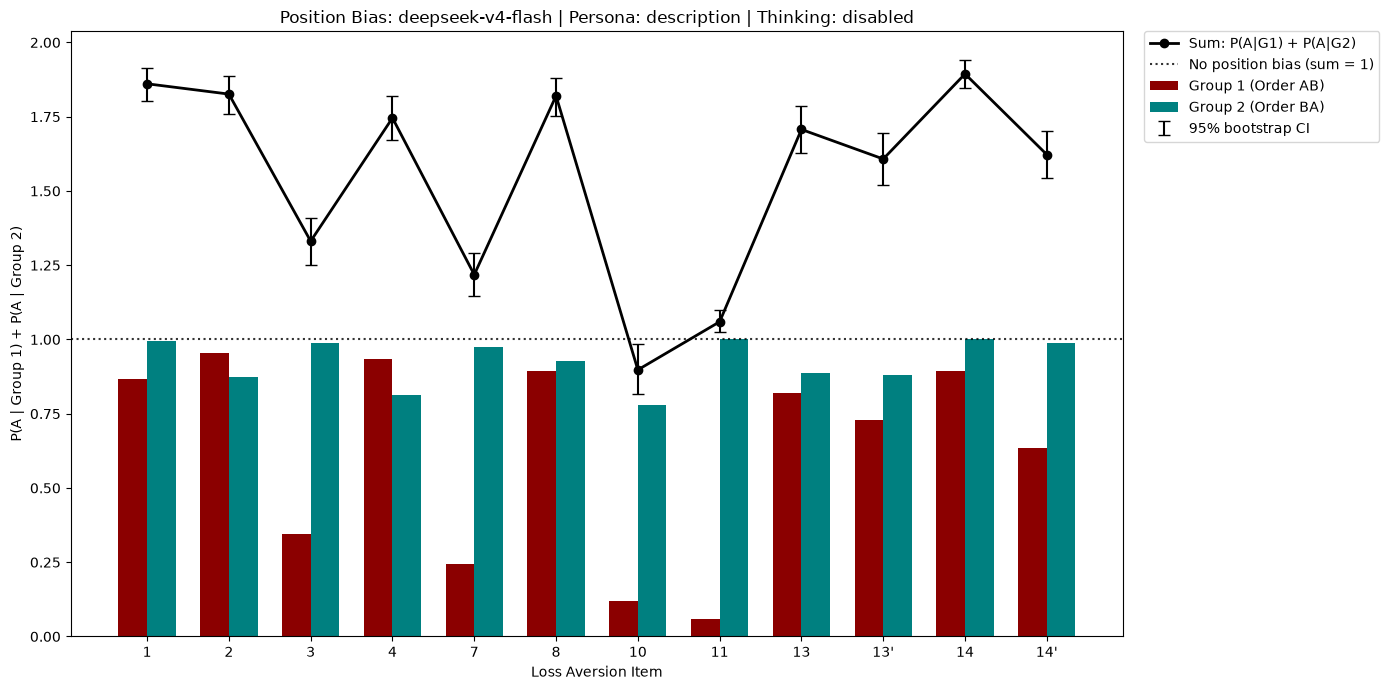

--------------------------------------------------------------------------------
Overall position bias across all items: 0.549, P(A) = 0.775
95% CI: [0.524, 0.574]
Significant: True
--------------------------------------------------------------------------------


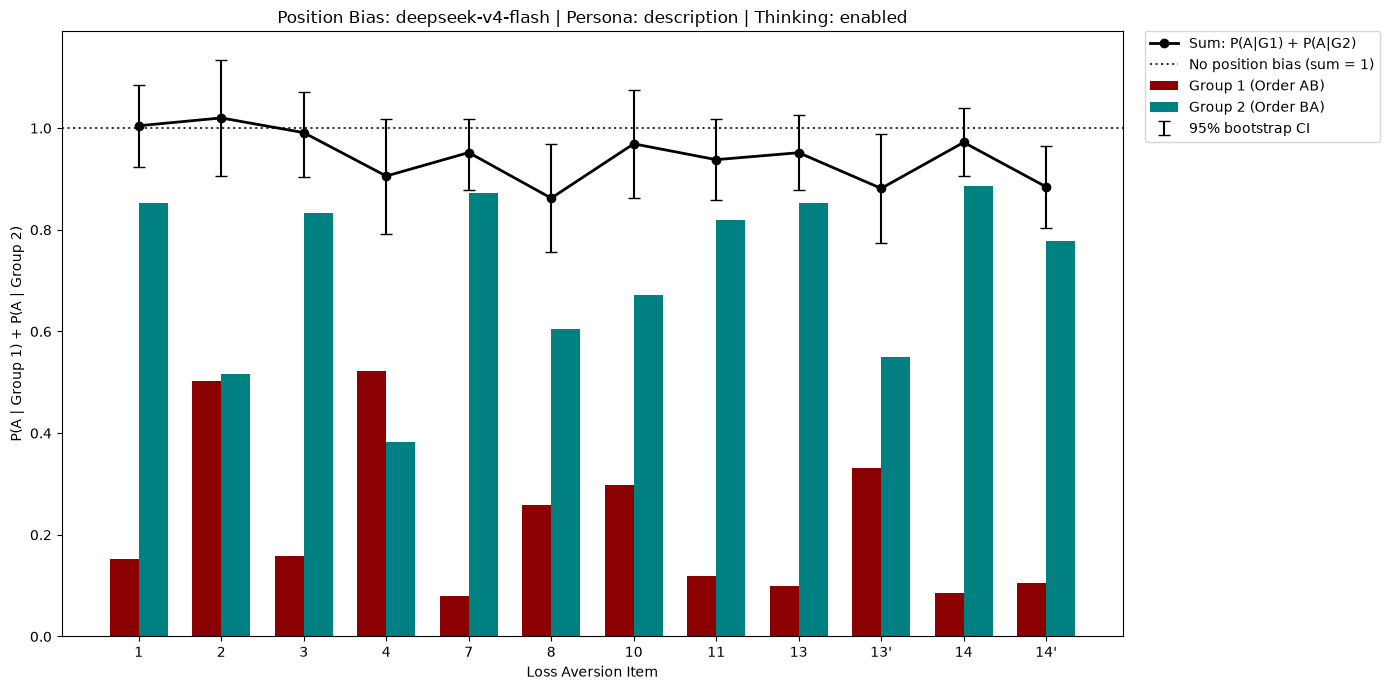

--------------------------------------------------------------------------------
Overall position bias across all items: -0.056, P(A) = 0.472
95% CI: [-0.121, 0.010]
Significant: False
--------------------------------------------------------------------------------


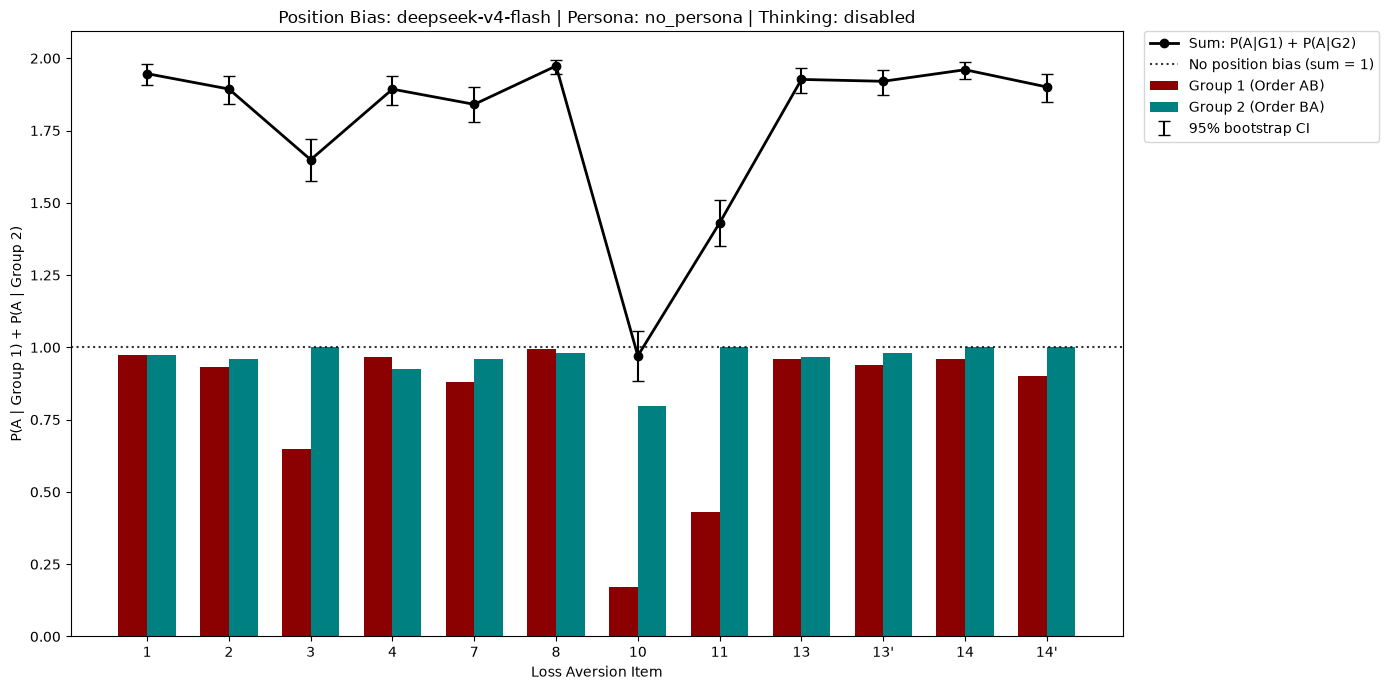

--------------------------------------------------------------------------------
Overall position bias across all items: 0.775, P(A) = 0.888
95% CI: [0.759, 0.791]
Significant: True
--------------------------------------------------------------------------------


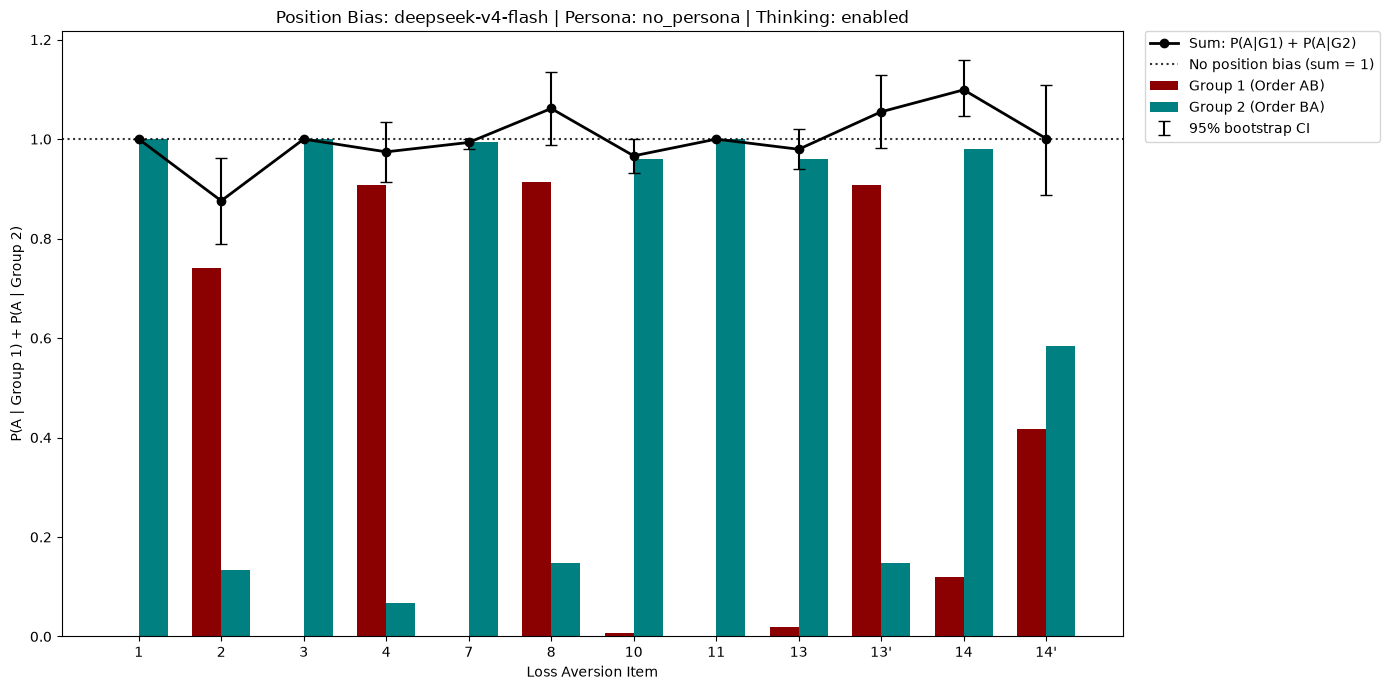

--------------------------------------------------------------------------------
Overall position bias across all items: 0.001, P(A) = 0.500
95% CI: [-0.017, 0.018]
Significant: False
--------------------------------------------------------------------------------


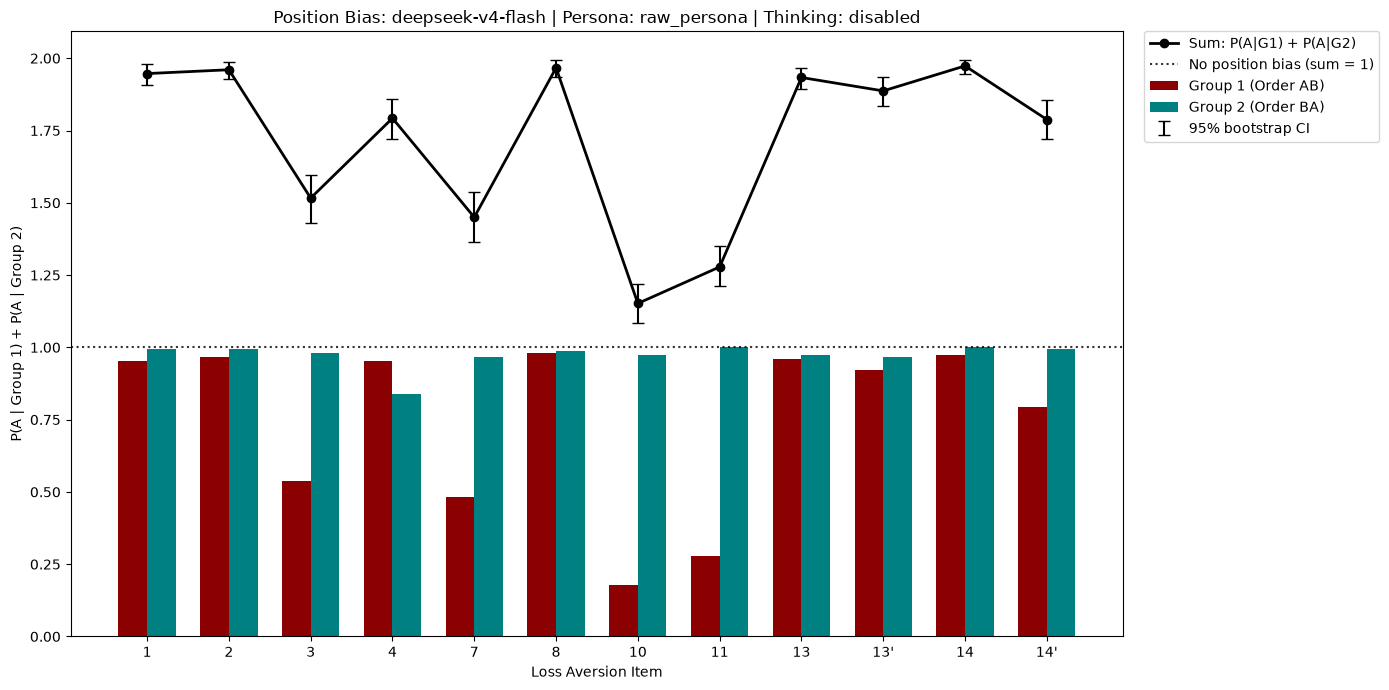

--------------------------------------------------------------------------------
Overall position bias across all items: 0.720, P(A) = 0.860
95% CI: [0.702, 0.738]
Significant: True
--------------------------------------------------------------------------------


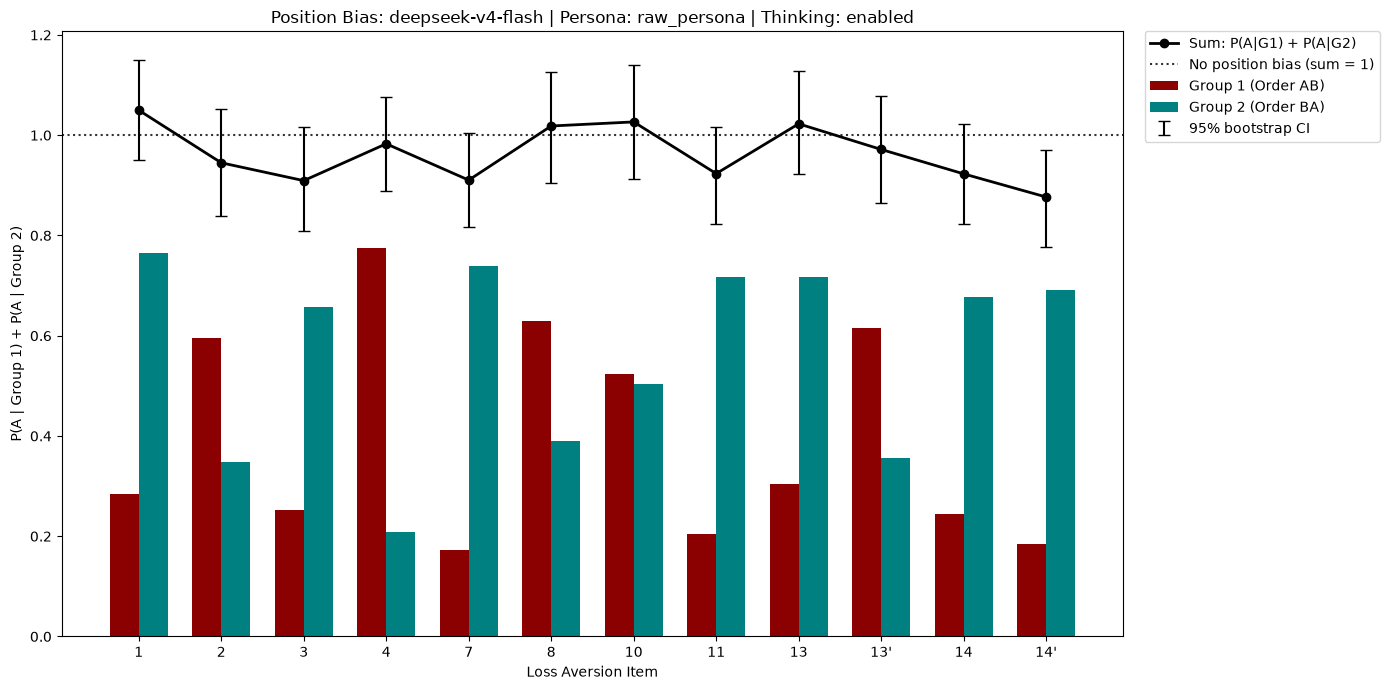

--------------------------------------------------------------------------------
Overall position bias across all items: -0.037, P(A) = 0.482
95% CI: [-0.106, 0.033]
Significant: False
--------------------------------------------------------------------------------


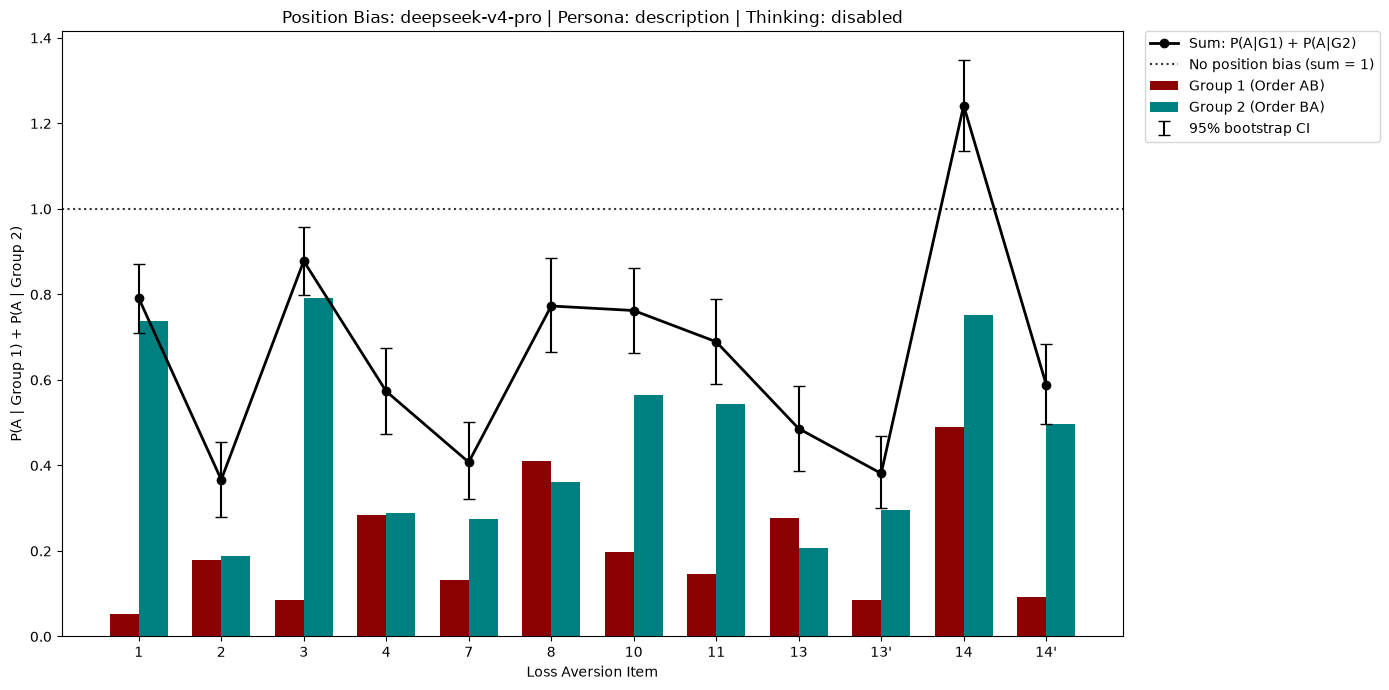

--------------------------------------------------------------------------------
Overall position bias across all items: -0.338, P(A) = 0.331
95% CI: [-0.372, -0.306]
Significant: True
--------------------------------------------------------------------------------


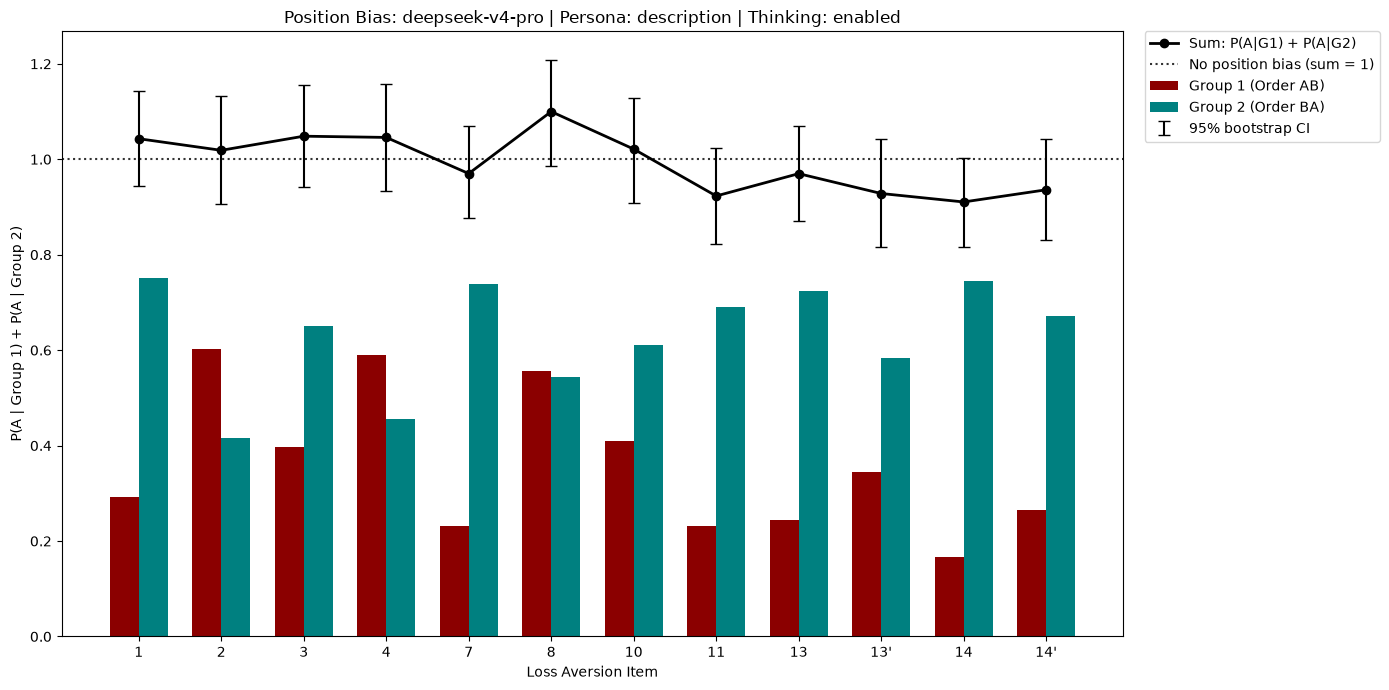

--------------------------------------------------------------------------------
Overall position bias across all items: -0.007, P(A) = 0.496
95% CI: [-0.087, 0.072]
Significant: False
--------------------------------------------------------------------------------


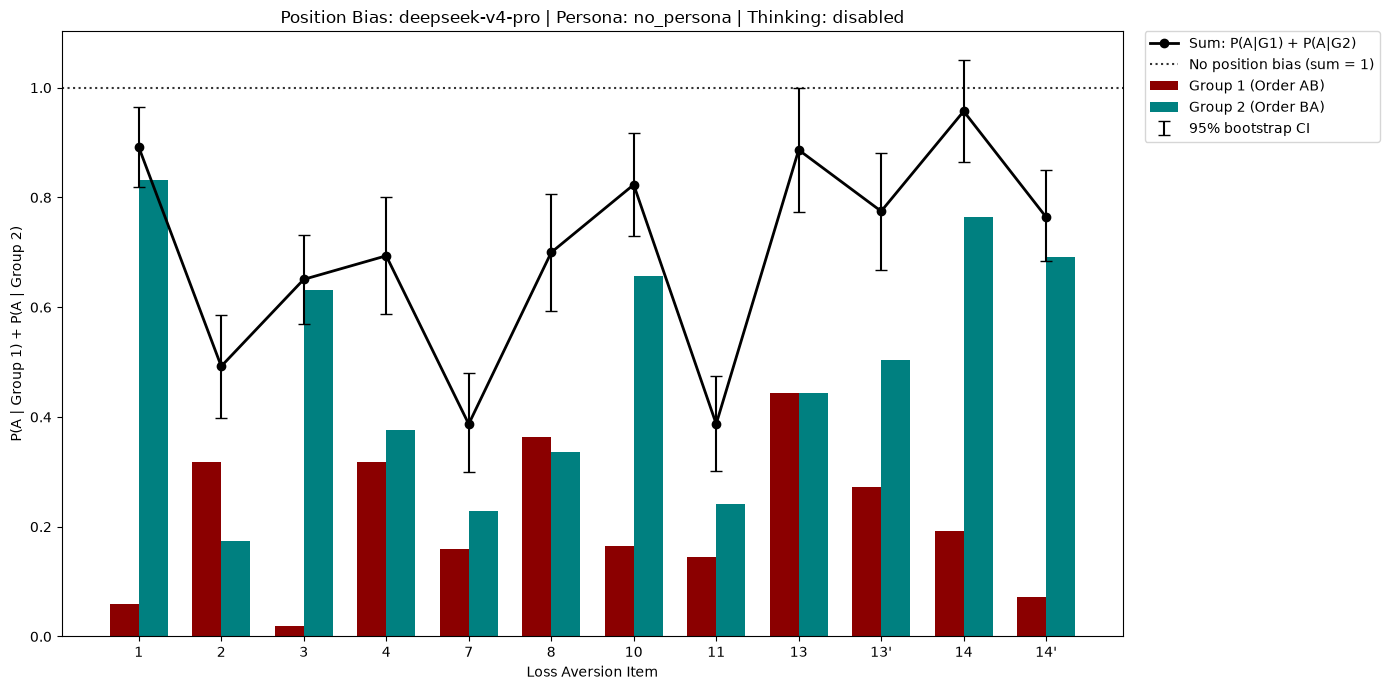

--------------------------------------------------------------------------------
Overall position bias across all items: -0.299, P(A) = 0.350
95% CI: [-0.327, -0.272]
Significant: True
--------------------------------------------------------------------------------


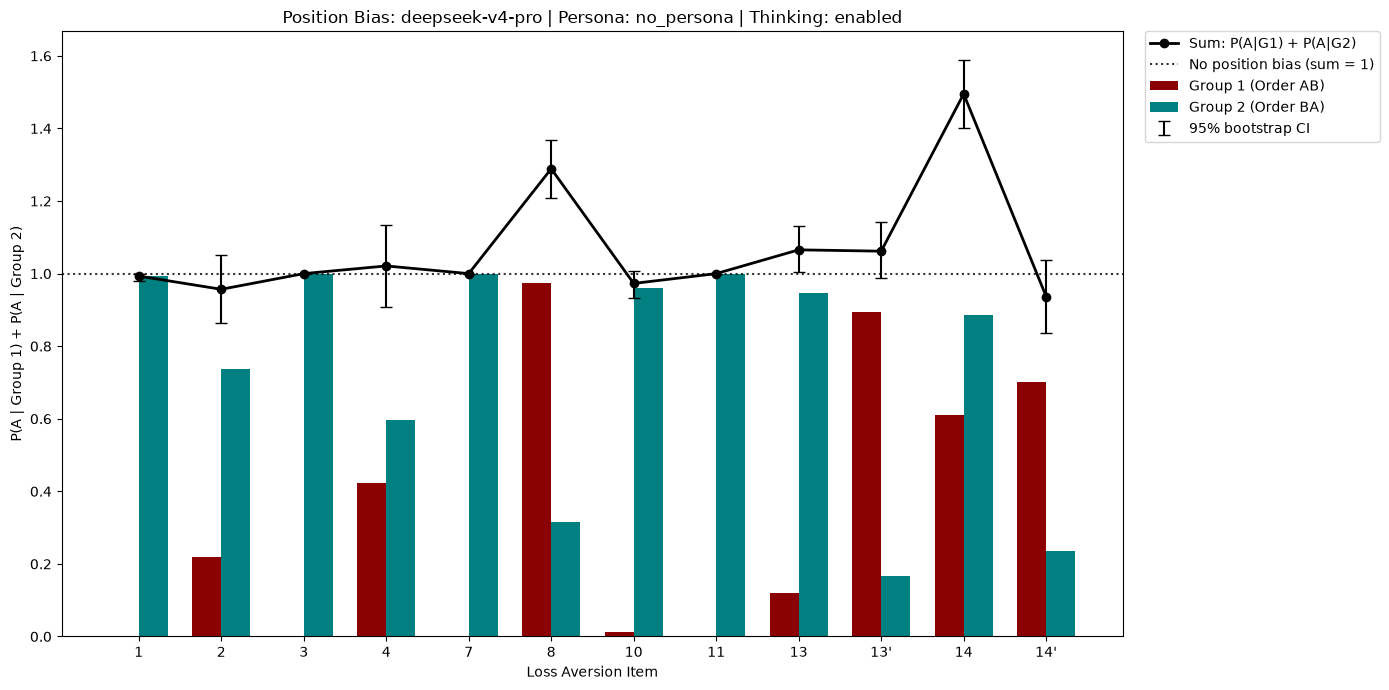

--------------------------------------------------------------------------------
Overall position bias across all items: 0.066, P(A) = 0.533
95% CI: [0.046, 0.087]
Significant: True
--------------------------------------------------------------------------------


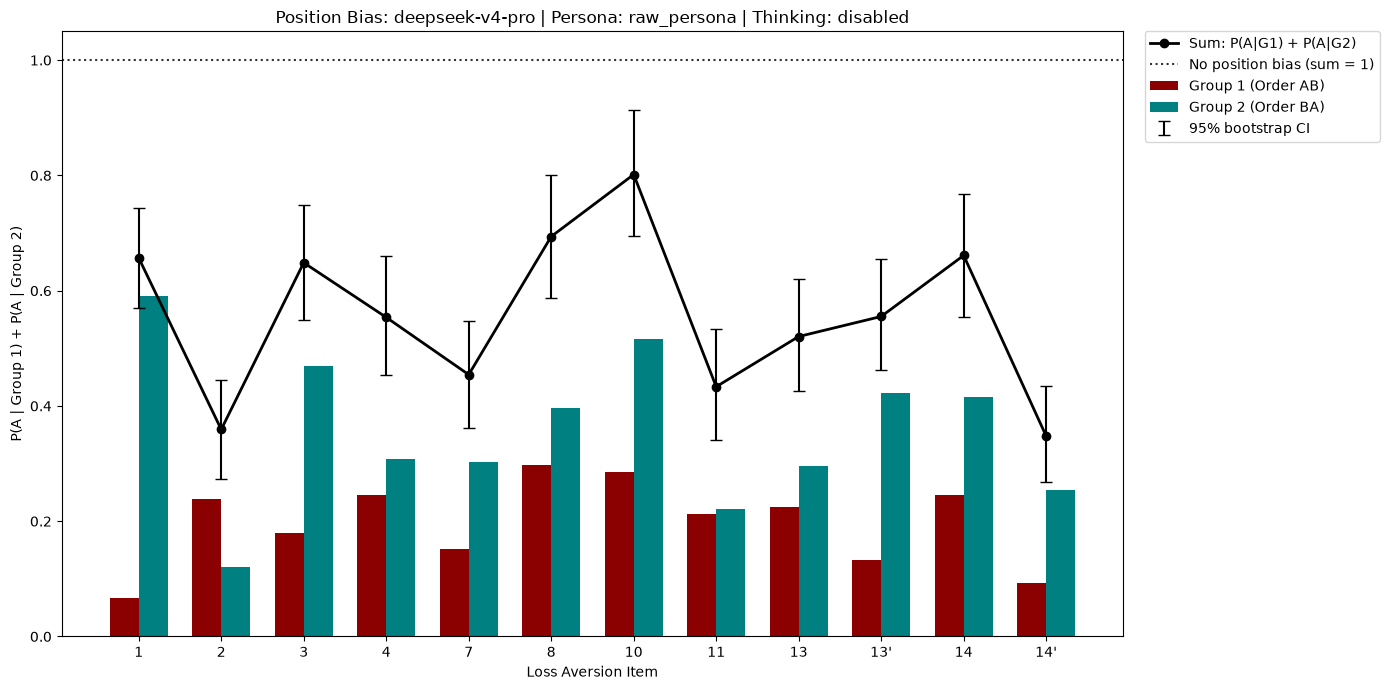

--------------------------------------------------------------------------------
Overall position bias across all items: -0.443, P(A) = 0.279
95% CI: [-0.471, -0.414]
Significant: True
--------------------------------------------------------------------------------


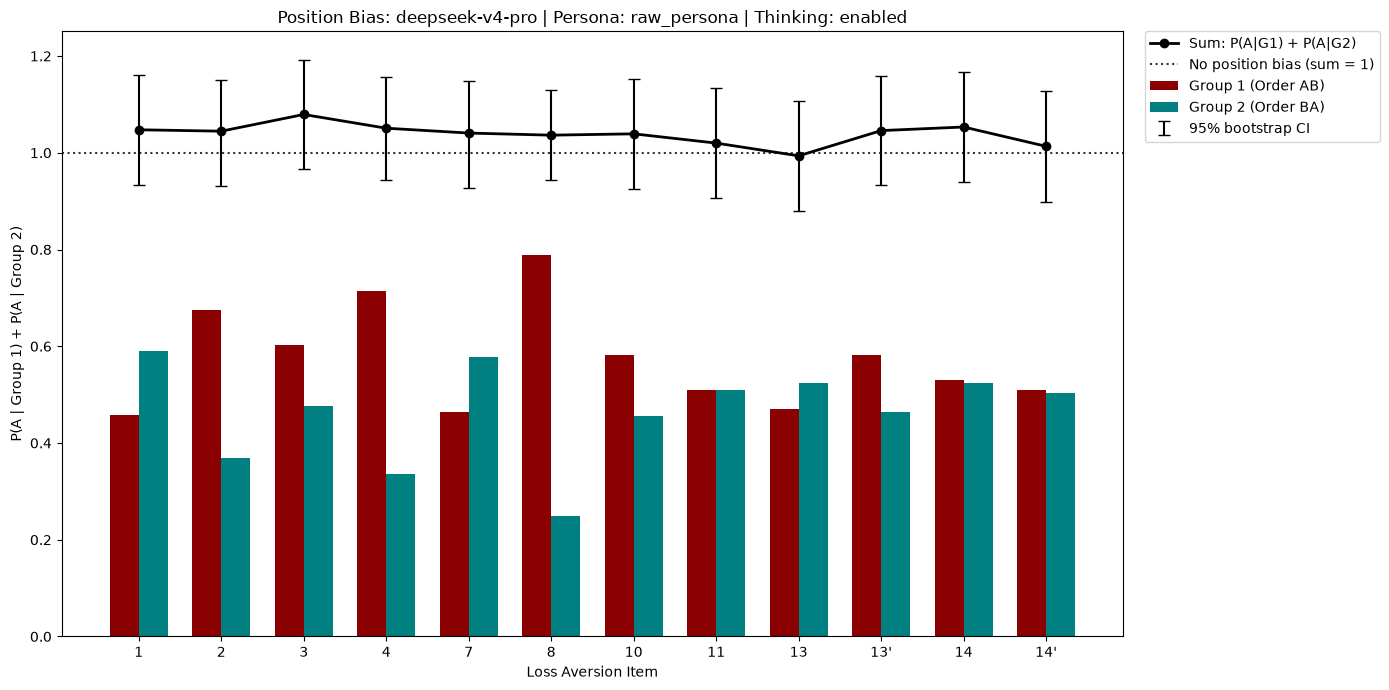

--------------------------------------------------------------------------------
Overall position bias across all items: 0.039, P(A) = 0.519
95% CI: [-0.047, 0.123]
Significant: False
--------------------------------------------------------------------------------


In [37]:
position_bias_rows = []
for (llm, persona, thinking), condition_df in df.groupby(["llm", "persona", "thinking"]):

    item_summary, summary, bootstrap_statistics = test_position_bias(condition_df)
    # create for postion bias df
    position_bias_rows.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "position_bias": summary["position_bias"].iloc[0],
        "position_bias_p_A": summary["position_bias_p_A"].iloc[0],
        "position_bias_lower_95CI": summary["lower_95CI"].iloc[0],
        "position_bias_upper_95CI": summary["upper_95CI"].iloc[0],
        "position_bias_significant": summary["significant_first_position_bias"].iloc[0]
    })
    
    title = (
        f"Position Bias: {llm} | "
        f"Persona: {persona} | "
        f"Thinking: {thinking}"
    )

    plot_position_bias(
        item_summary=item_summary,
        title=title
    )
    print("-" * 80)
    print(f"Overall position bias across all items: {summary['position_bias'].iloc[0]:.3f}, P(A) = {summary['position_bias_p_A'].iloc[0]:.3f}")
    print(f"95% CI: [{summary['lower_95CI'].iloc[0]:.3f}, {summary['upper_95CI'].iloc[0]:.3f}]")
    print(f"Significant: {summary['significant_first_position_bias'].iloc[0]}")
    print("-" * 80)
position_bias_summary = pd.DataFrame(position_bias_rows)

In [11]:
# Invert the responses for group 2
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]
mask = df["experiment_group"] == 2
swap = {"A": "B", "B": "A"}
df.loc[mask, cols] = df.loc[mask, cols].replace(swap)
print(f"Total missing values across df: {df.isna().sum().sum()}")
# df = df.dropna(axis=0)
# df

Total missing values across df: 0


Read data from [Ruggeri et al., (2020)](https://osf.io/esxc4/overview) for human comparison and remap the items to match the original prospect theory items (and by extension my order)

In [13]:
long_data = pd.read_csv("../prospect_theory_meta_analysis_data/proportions_by_country.csv")
prop_df = pd.read_csv("../prospect_theory_meta_analysis_data/Meta analysis proportions.csv")
original_pt_proportions_df = pd.read_csv("../prospect_theory_meta_analysis_data/original_proportions.csv")

# recode to match with original paper item order
# 13 == 12 which is corrupted in my thesis
long_data = long_data[~long_data["Item"].isin([7, 8, 9, 10, 13])].copy()
item_mapping = {
    1: "1",
    2: "2",
    3: "3",
    4: "4",
    5: "7",
    6: "8",
    11: "10",
    12: "11",
    14: "13",
    15: "13'",
    16: "14",
    17: "14'"
}
long_data["Item"] = long_data["Item"].map(item_mapping)
long_data.loc[long_data["Succesful Replication"].isna(),"Succesful Replication"] = "NA"

prop_df = prop_df[~prop_df["Item"].isin([7, 8, 9, 10, 13])].copy()
prop_df["Item"] = prop_df["Item"].map(item_mapping)

original_pt_proportions_df = original_pt_proportions_df[~original_pt_proportions_df["Item"].isin([7, 8, 9, 10, 13])].copy()
original_pt_proportions_df["Item"] = original_pt_proportions_df["Item"].map(item_mapping)

calculate A response proportion and data transformation to align df for plotting

In [14]:
excluded = {"Loss_Aversion_5", "Loss_Aversion_6", "Loss_Aversion_9", "Loss_Aversion_12"}
loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion") and col not in excluded]

# Long format
long_df = df.melt(
    id_vars=["llm", "persona", "thinking"],
    value_vars=loss_cols,
    var_name="question",
    value_name="answer"
)

results = []
for (llm, persona, thinking, question), group in long_df.groupby(["llm", "persona", "thinking", "question"]):

    n_A = (group["answer"] == "A").sum()
    n = len(group)
    pct_A = n_A / n

    results.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "question": question,
        "n": n,
        "n_A": n_A,
        "A_proportion": pct_A,
    })

results = pd.DataFrame(results)
results = results.sort_values(["llm", "persona", "thinking", "question"])
llm_item_mapping = {
    "Loss_Aversion_1": "1",
    "Loss_Aversion_2": "2",
    "Loss_Aversion_3": "3",
    "Loss_Aversion_4": "4",
    "Loss_Aversion_7": "7",
    "Loss_Aversion_8": "8",
    "Loss_Aversion_10": "10",
    "Loss_Aversion_11": "11",
    "Loss_Aversion_13": "13",
    "Loss_Aversion_13_inverse": "13'",
    "Loss_Aversion_14": "14",
    "Loss_Aversion_14_inverse": "14'"
}
results["Item"] = results["question"].map(llm_item_mapping)

item_order = list(llm_item_mapping.values())
item_to_x = {item: i for i, item in enumerate(item_order)}

original_pt_proportions_df["x_pos"] = (original_pt_proportions_df["Item"].map(item_to_x))
prop_df["x_pos"] = (prop_df["Item"].map(item_to_x))
long_data["x_pos"] = (long_data["Item"].map(item_to_x))
results["x_pos"] = (results["Item"].map(item_to_x))

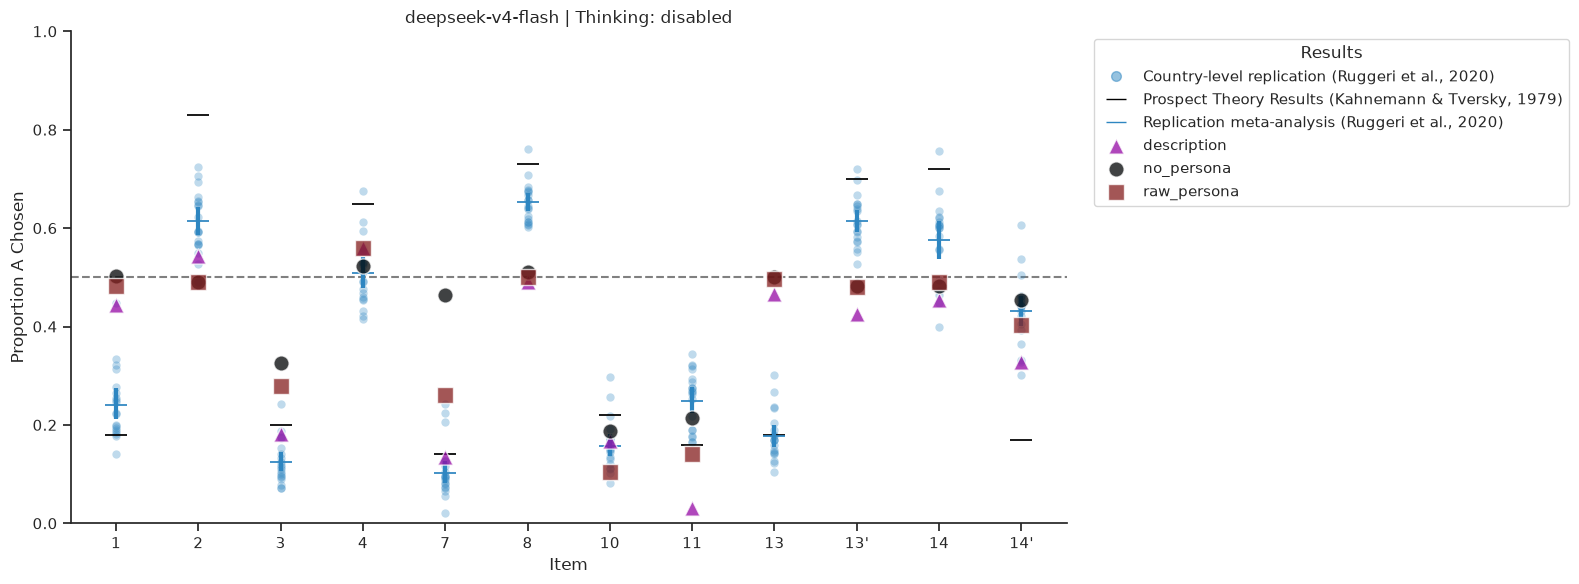

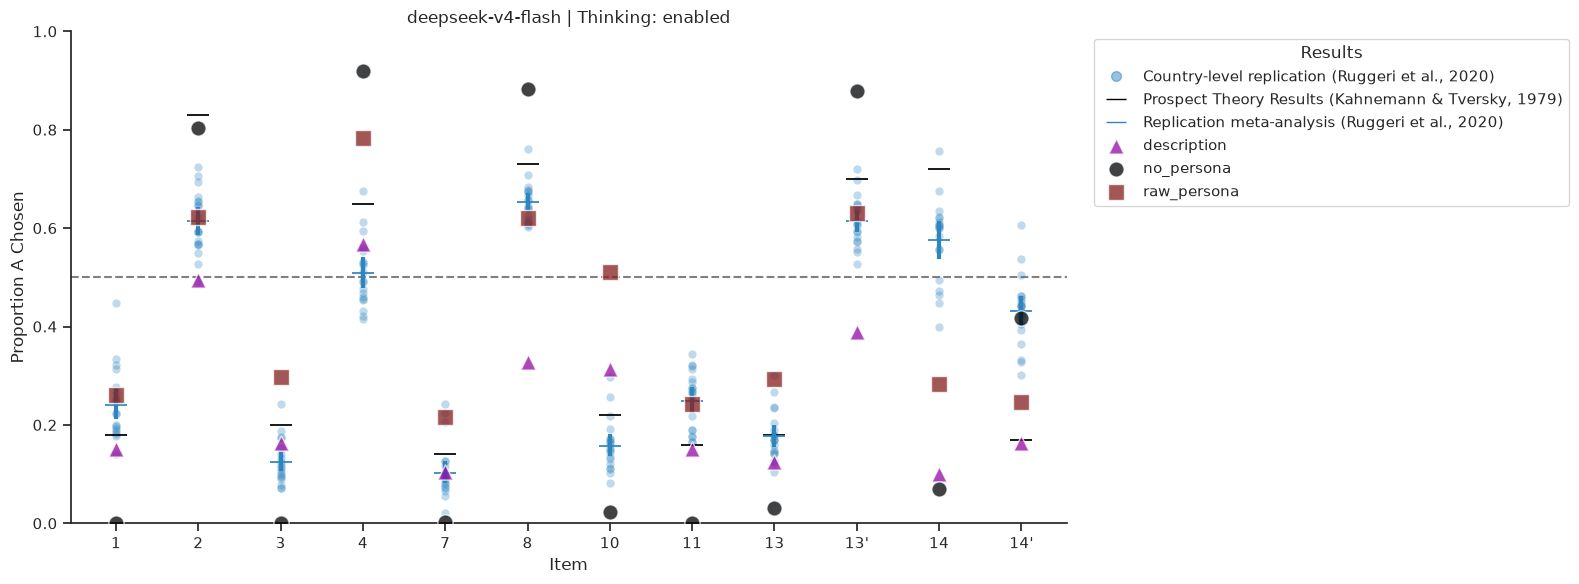

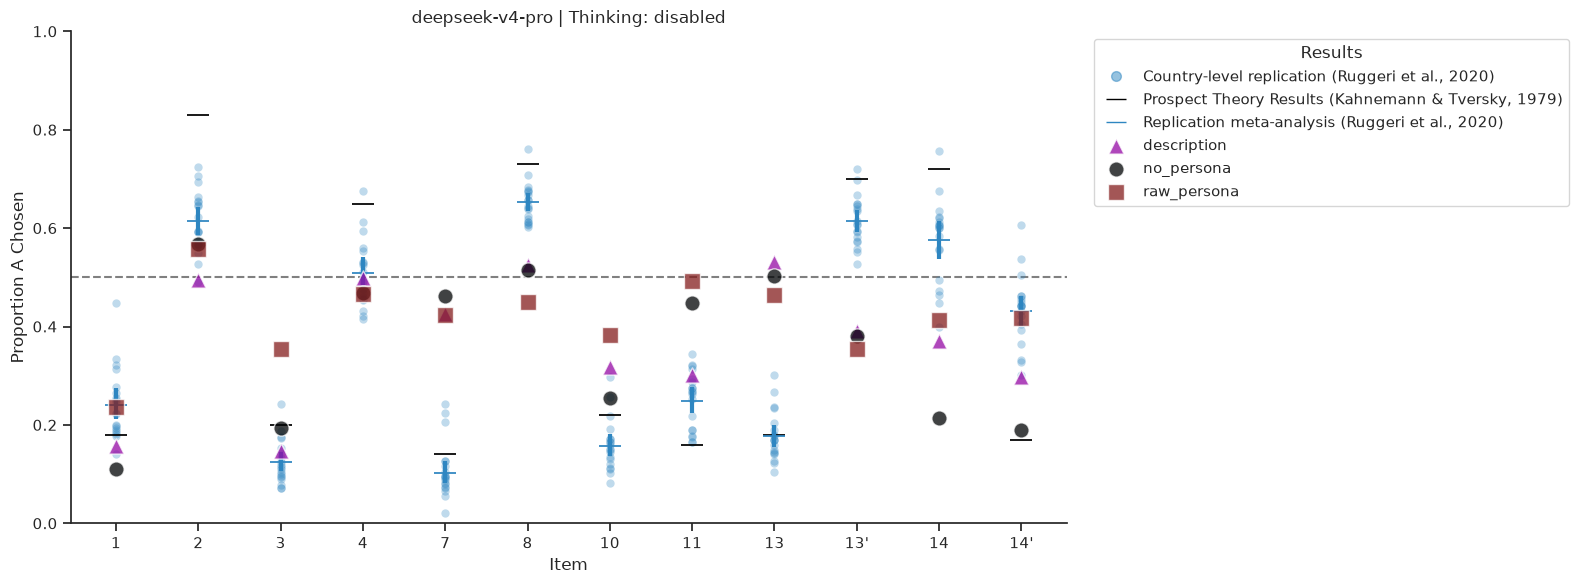

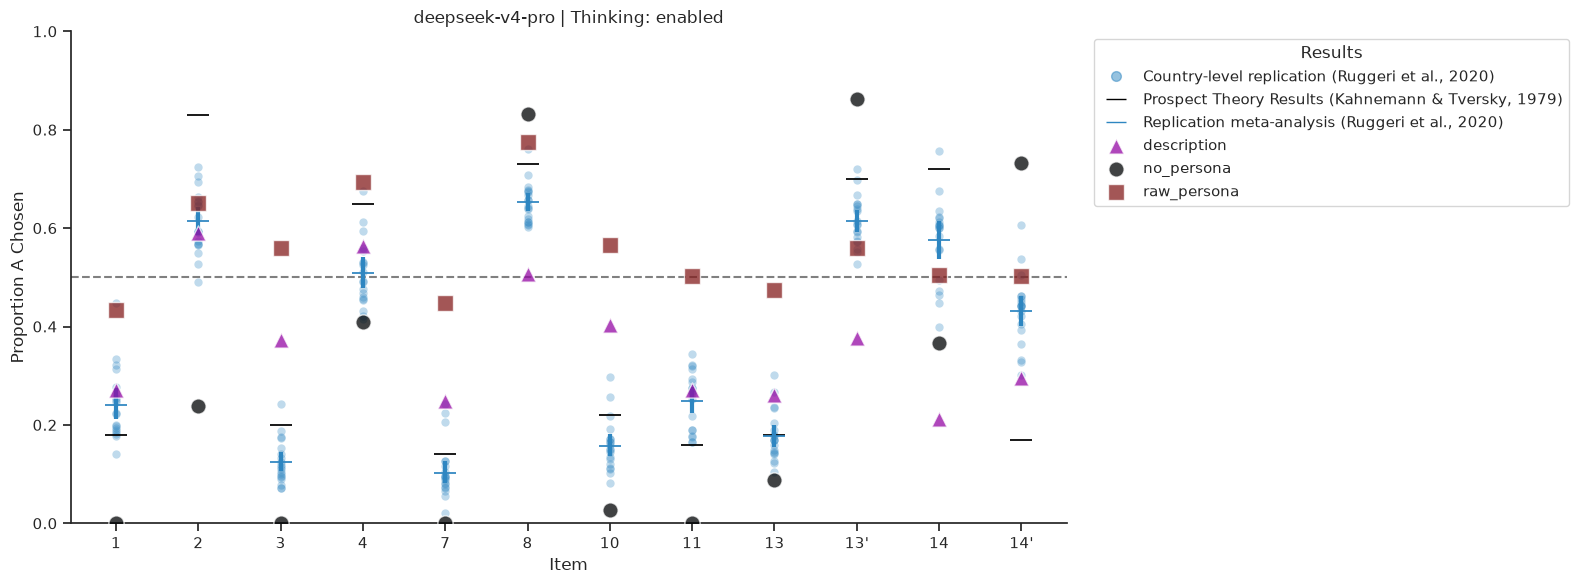

In [15]:
# also plot 5, 6 and 9?
sns.set_theme(font_scale=1, style="ticks")

# Markers for the three persona conditions
persona_markers = {
    "no_persona": "o",
    "raw_persona": "s",
    "description": "^"
}

# Colors for the three persona conditions
persona_colors = {
    "no_persona": "#000304",
    "raw_persona": "#841E1E",
    "description": "#9409a4"
}


for (llm, thinking), group_df in results.groupby(["llm", "thinking"]):

    fig, ax = plt.subplots(figsize=(16, 6))


    # COUNTRY-LEVEL REPLICATION DATA FROM Ruggeri et al., 2020
    sns.scatterplot(
        x="x_pos",
        y="Proportion",
        data=long_data,
        # hue="Succesful Replication",
        # hue_order=["Yes", "No", "NA"],
        # style="Succesful Replication",
        linewidth=0,
        alpha=0.3,
        color="#2e86c1",
        markers="o",
        ax=ax,
        zorder=1,
        legend=False
    )


    # ORIGINAL KAHNEMAN & TVERSKY
    sns.scatterplot(
        data=original_pt_proportions_df,
        x="x_pos",
        y="Proportion",
        marker="_",
        s=250,
        color="black",
        ax=ax,
        zorder=2,
        legend=False
    )


    # REPLICATION META-ANALYSIS
    sns.scatterplot(
        data=prop_df,
        x="x_pos",
        y="prop",
        # hue="Succesful Replication",
        # hue_order=["Yes", "No", "NA"],
        marker="_",
        s=250,
        color="#2e86c1",
        ax=ax,
        zorder=4,
        legend=False
    )

    # META-ANALYSIS ERROR BARS
    for _, row in prop_df.dropna(subset=["x_pos"]).iterrows():

        x = int(row["x_pos"])

        lower_error = row["prop"] - row["lb"]
        upper_error = row["ub"] - row["prop"]

        ax.errorbar(
            x,
            row["prop"],
            yerr=[
                [lower_error],
                [upper_error]
            ],
            linestyle="",
            linewidth=3,
            color="#2e86c1",
            capsize=0,
            zorder=3
        )


    # LLM REPLICATION RESULTS
    for persona, persona_df in group_df.groupby("persona"):

        sns.scatterplot(
            data=persona_df,
            x="x_pos",
            y="A_proportion",
            marker=persona_markers.get(persona, "o"),
            s=120,
            color=persona_colors.get(persona, "black"),
            edgecolor="white",
            linewidth=1,
            ax=ax,
            zorder=5,
            label=persona,
            alpha=.75
        )


    # INDIFFERENCE LINE
    ax.axhline(
        y=0.5,
        linestyle="--",
        color="grey",
        zorder=0
    )


    ax.set_xticks(range(len(item_order)))
    ax.set_xticklabels(item_order)
    ax.set_xlabel("Item")
    ax.set_ylabel("Proportion A Chosen")
    ax.set_ylim(0, 1)
    ax.set_title(f"{llm} | Thinking: {thinking}")
    handles, labels = ax.get_legend_handles_labels()

    from matplotlib.lines import Line2D
    handles = [
        Line2D([], [], marker="o", color="#2e86c1",
               linestyle="none", markersize=7,
               alpha=0.5, label="Country-level replication (Ruggeri et al., 2020)"),

        Line2D([], [], marker="_", color="black",
               linestyle="none", markersize=14,
               label="Prospect Theory Results (Kahnemann & Tversky, 1979)"),

        Line2D([], [], marker="_", color="#2e86c1",
               linestyle="none", markersize=14,
               label="Replication meta-analysis (Ruggeri et al., 2020)")
    ] + handles

    labels = [
        "Country-level replication (Ruggeri et al., 2020)",
        "Prospect Theory Results (Kahnemann & Tversky, 1979)",
        "Replication meta-analysis (Ruggeri et al., 2020)"
    ] + labels

    ax.legend(
        handles=handles,
        labels=labels,
        title="Results",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    sns.despine()
    plt.tight_layout()

In [17]:
prospect_theory_raw_data = pd.read_csv("../prospect_theory_meta_analysis_data/pt_replication_modified_exclusions_data.csv", index_col=0) # 1 == A response

# Recode item numbers to match the original paper's (and this thesis) item order
item_mapping = {
    "1": "1",
    "2": "2",
    "3": "3",
    "4": "4",
    "5": "7",
    "6": "8",
    "11": "10",
    "12": "11",
    "14": "13",
    "15": "13'",
    "16": "14",
    "17": "14'"
}

prospect_theory_raw_data = (
    prospect_theory_raw_data
    .loc[:, prospect_theory_raw_data.columns.astype(str).isin(item_mapping.keys())]
    .rename(columns=item_mapping)
)

In [18]:
N_BOOTSTRAPS = 10_000
rng = np.random.default_rng(1)

bootstrap_results = []

# Human data
human_values = prospect_theory_raw_data.to_numpy(dtype=float)
n_humans = human_values.shape[0]
human_items = list(prospect_theory_raw_data.columns)


# LLM data
excluded = {"Loss_Aversion_5", "Loss_Aversion_6", "Loss_Aversion_9", "Loss_Aversion_12"}
loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion") and col not in excluded]

for (llm, persona, thinking), condition in df.groupby( ["llm", "persona", "thinking"]):

    llm_values = condition[loss_cols].to_numpy()
    n_llm = llm_values.shape[0]

    for i in range(N_BOOTSTRAPS):

        # Resample LLM participants
        llm_idx = rng.integers(0, n_llm, size=n_llm)
        llm_sample = llm_values[llm_idx]
        p_llm = (llm_sample == "A").mean(axis=0)


        # Resample human participants independently
        human_idx = rng.integers(0, n_humans, size=n_humans)
        human_sample = human_values[human_idx]
        p_human = np.nanmean(human_sample, axis=0)

        # Random Baseline
        random_sample = rng.integers(0, 2, size=(n_llm, len(loss_cols)))
        p_random = (random_sample == 0).mean(axis=0)

        # Directly calculate LLM - human difference
        delta = p_llm - p_human


        # Store bootstrap results
        for question, a_llm, a_human, a_random, d in zip(loss_cols, p_llm, p_human, p_random, delta):

            question_clean = (
                question
                .replace("Loss_Aversion_", "")
                .replace("_inverse", "'")
            )

            bootstrap_results.append({
                "llm": llm,
                "persona": persona,
                "thinking": thinking,
                "question": question_clean,
                "bootstrap": i,
                "delta": d,
                "absolute_error": abs(d),
                "A_p_llm": a_llm,
                "A_p_human": a_human,
                "A_p_random": a_random
            })

bootstrap_delta = pd.DataFrame(bootstrap_results)

# Observed human proportion
human_obs = (
    prospect_theory_raw_data
    .mean()
    .rename("p_human")
    .reset_index()
    .rename(columns={"index": "question"})
)


# Observed LLM proportion
llm_obs = (
    df.melt(
        id_vars=["llm", "persona", "thinking"],
        value_vars=loss_cols,
        var_name="question",
        value_name="answer"
    )
    .assign(p_llm=lambda x: (x["answer"] == "A").astype(float))
    .groupby(["llm", "persona", "thinking", "question"])["p_llm"]
    .mean()
    .reset_index()
)

llm_obs["question"] = (
    llm_obs["question"]
    .str.replace("Loss_Aversion_", "", regex=False)
    .str.replace("_inverse", "'", regex=False)
)


# Observed delta
delta_summary = llm_obs.merge(human_obs, on="question")
delta_summary["delta"] = (delta_summary["p_llm"] - delta_summary["p_human"])


# Bootstrap 95% CI
delta_ci = (
    bootstrap_delta
    .groupby(["llm", "persona", "thinking", "question"])["delta"]
    .agg(
        lower_95CI=lambda x: x.quantile(0.025),
        upper_95CI=lambda x: x.quantile(0.975)
    )
    .reset_index()
)

delta_summary = delta_summary.merge(delta_ci,on=["llm", "persona", "thinking", "question"])
delta_summary

,llm,persona,thinking,question,p_llm,p_human,delta,lower_95CI,upper_95CI
0,deepseek-v4-flash,description,disabled,1,0.442953,0.254758,0.188195,0.130049,0.247506
1,deepseek-v4-flash,description,disabled,10,0.167785,0.160566,0.007219,-0.035430,0.052127
2,deepseek-v4-flash,description,disabled,11,0.030201,0.253782,-0.223581,-0.246155,-0.199177
3,deepseek-v4-flash,description,disabled,13,0.466443,0.177852,0.288591,0.230680,0.345774
4,deepseek-v4-flash,description,disabled,13',0.426174,0.615745,-0.189571,-0.247067,-0.129992
...,...,...,...,...,...,...,...,...,...
139,deepseek-v4-pro,raw_persona,enabled,2,0.651877,0.617862,0.034015,-0.021810,0.090356
140,deepseek-v4-pro,raw_persona,enabled,3,0.559727,0.128355,0.431372,0.373839,0.487938
141,deepseek-v4-pro,raw_persona,enabled,4,0.692833,0.511713,0.181120,0.126500,0.233778
142,deepseek-v4-pro,raw_persona,enabled,7,0.447099,0.108590,0.338509,0.281462,0.396527


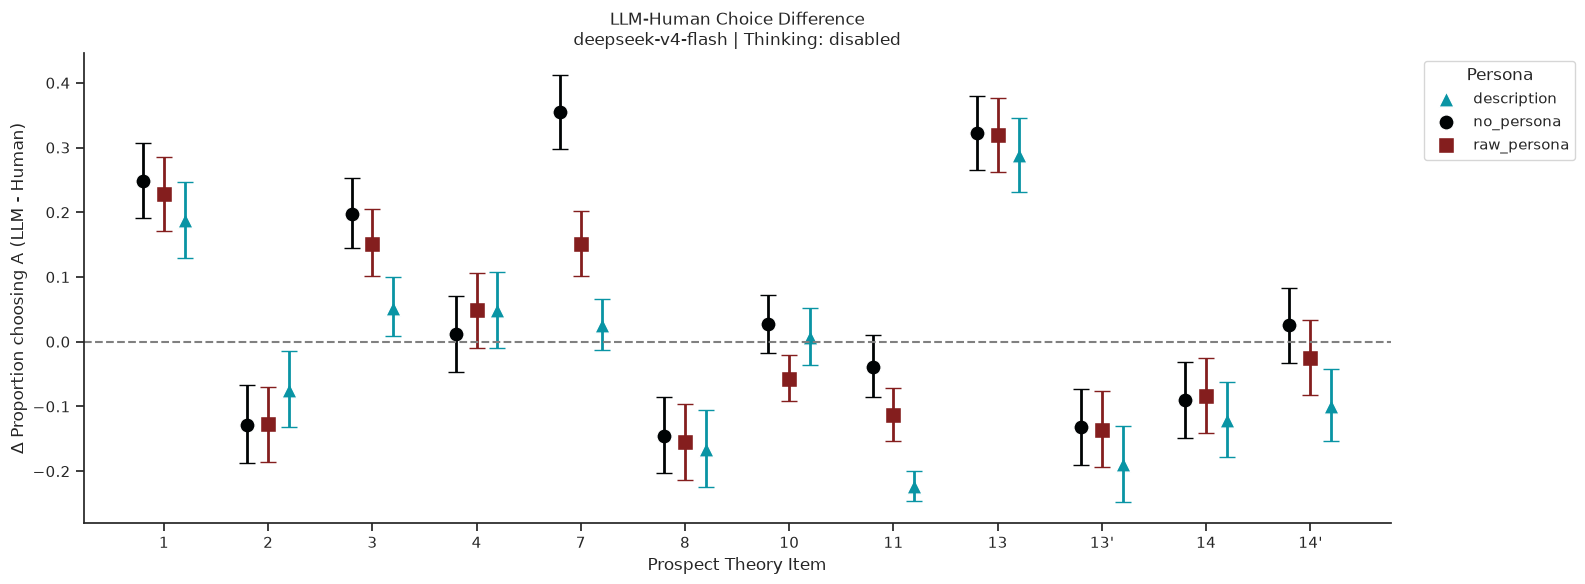

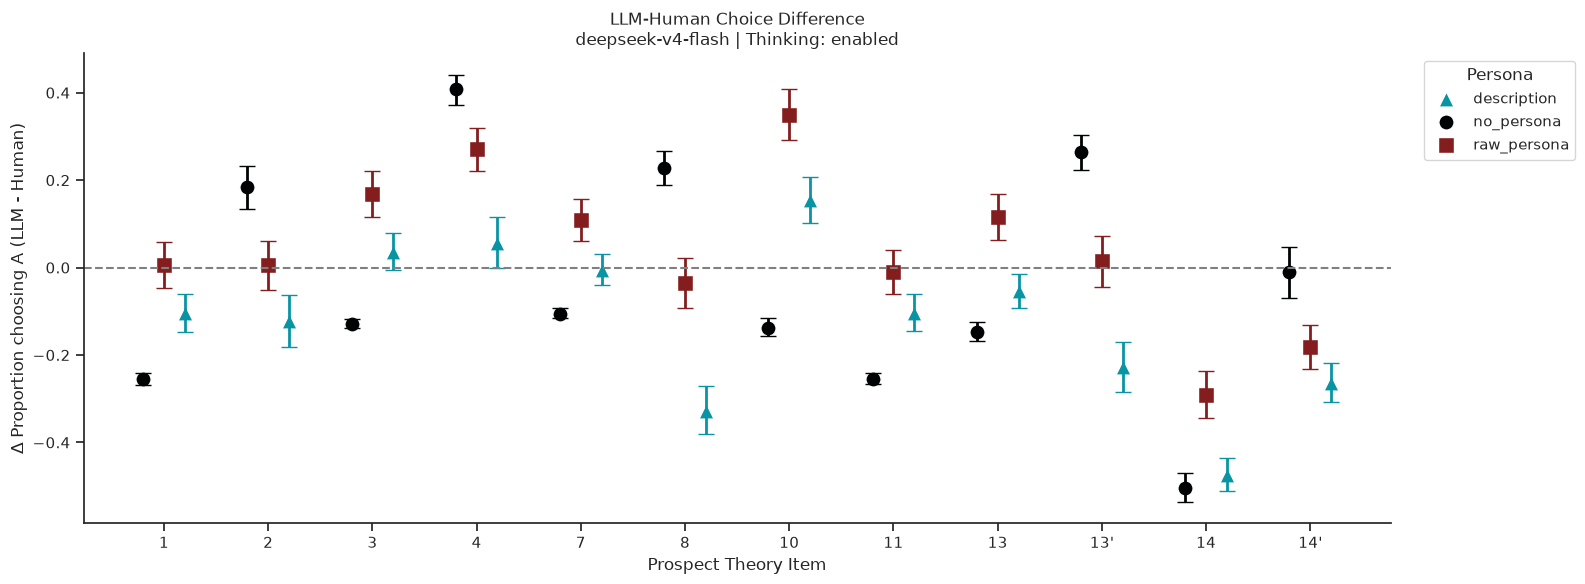

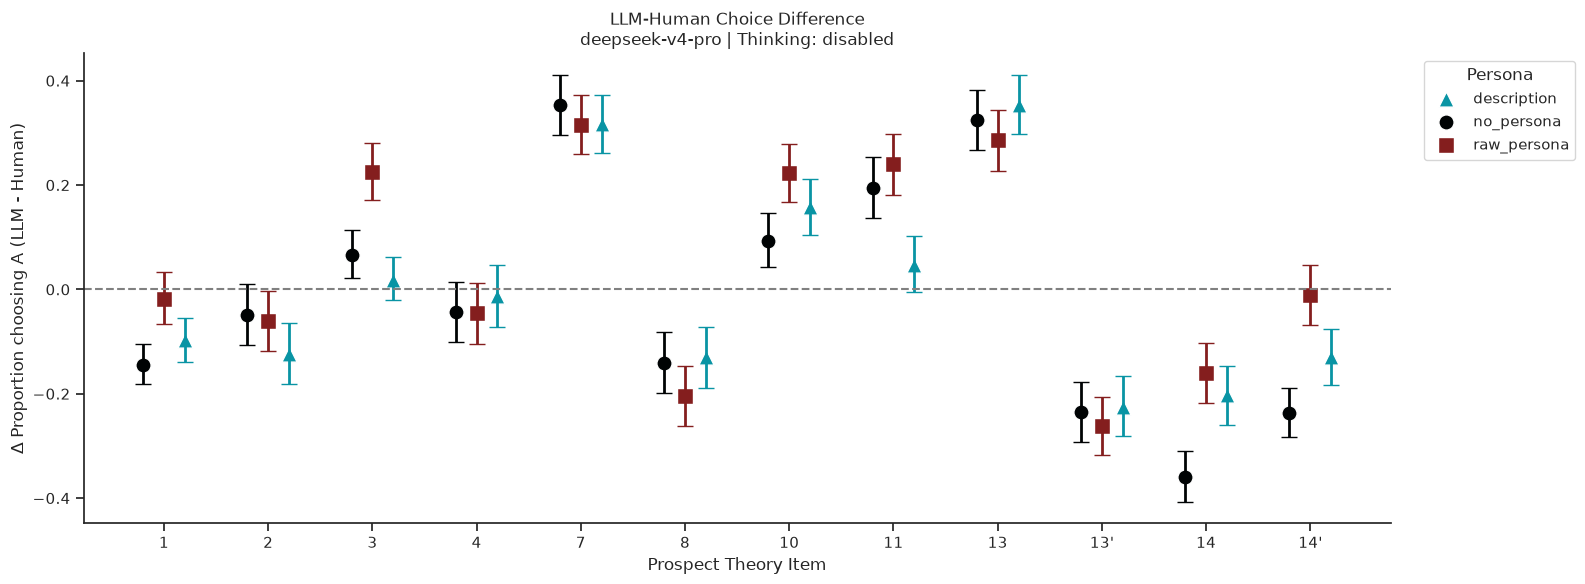

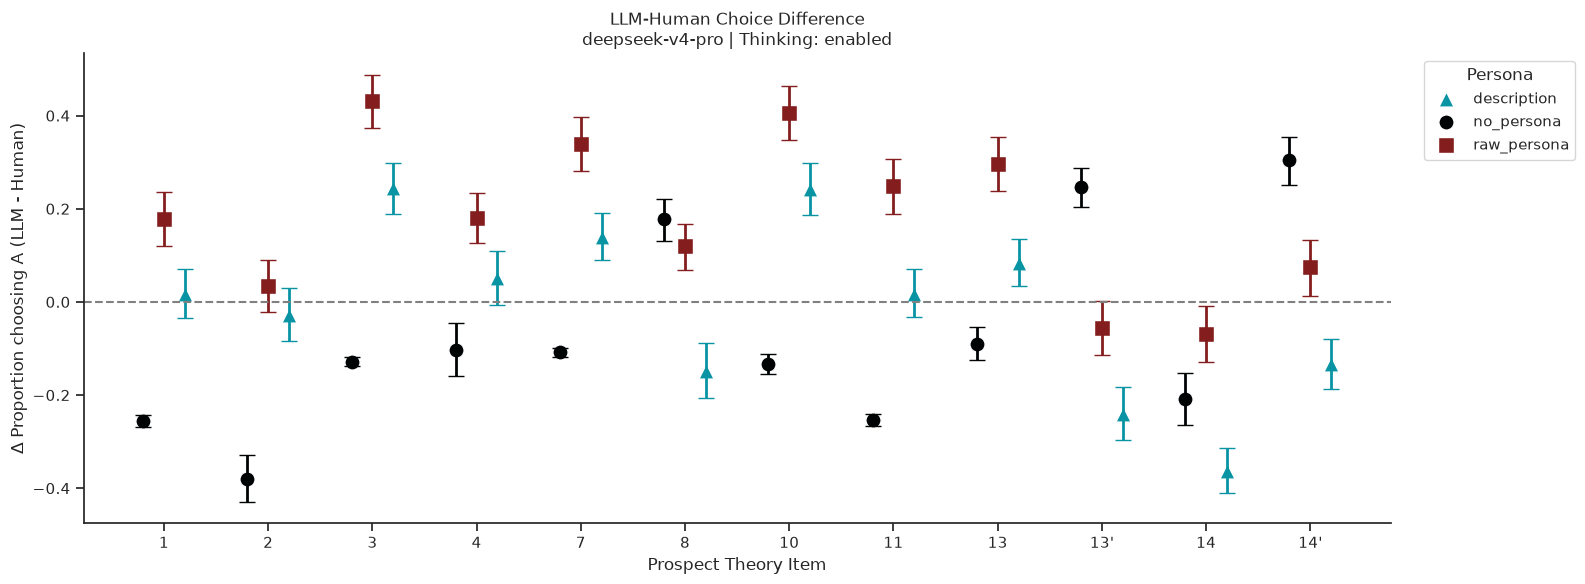

In [19]:
sns.set_theme(font_scale=1, style="ticks")
# Markers for the three persona conditions
persona_markers = {
    "no_persona": "o",
    "raw_persona": "s",
    "description": "^"
}

# Colors for the three persona conditions
persona_colors = {
    "no_persona": "#000304",
    "raw_persona": "#841E1E",
    "description": "#0994a4"
}
# Horizontal offsets so the three personas appear side-by-side
persona_offsets = {
    "no_persona": -0.20,
    "raw_persona": 0.00,
    "description": 0.20
}

for (llm, thinking), group_df in delta_summary.groupby(["llm", "thinking"]):

    fig, ax = plt.subplots(figsize=(16, 6))

    for persona, persona_df in group_df.groupby("persona"):

        # Make sure items are in the desired order
        persona_df = persona_df.copy()
        persona_df["x_pos"] = persona_df["question"].map(item_to_x)
        persona_df["x_pos"] += persona_offsets.get(persona, 0)
        persona_df = persona_df.sort_values("x_pos")
        color = persona_colors[persona]
        marker = persona_markers[persona]

        # Point estimate
        ax.scatter(
            persona_df["x_pos"],
            persona_df["delta"],
            marker=marker,
            s=120,
            color=color,
            edgecolor="white",
            linewidth=1,
            label=persona,
        )

        # 95% CI
        ax.errorbar(
            persona_df["x_pos"],
            persona_df["delta"],
            yerr=[
                persona_df["delta"] - persona_df["lower_95CI"],
                persona_df["upper_95CI"] - persona_df["delta"]
            ],
            fmt="none",
            ecolor=color,
            elinewidth=2,
            capsize=6
        )

    ax.axhline(
        y=0,
        linestyle="--",
        color="grey",
        linewidth=1.5,
    )

    ax.set_xticks(range(len(item_order)))
    ax.set_xticklabels(item_order)
    ax.set_xlabel("Prospect Theory Item")
    ax.set_ylabel("∆ Proportion choosing A (LLM - Human)")
    ax.set_title(f"LLM-Human Choice Difference\n{llm} | Thinking: {thinking}")
    ax.legend(title="Persona", bbox_to_anchor=(1.02, 1), loc="upper left")
    sns.despine()
    plt.tight_layout()

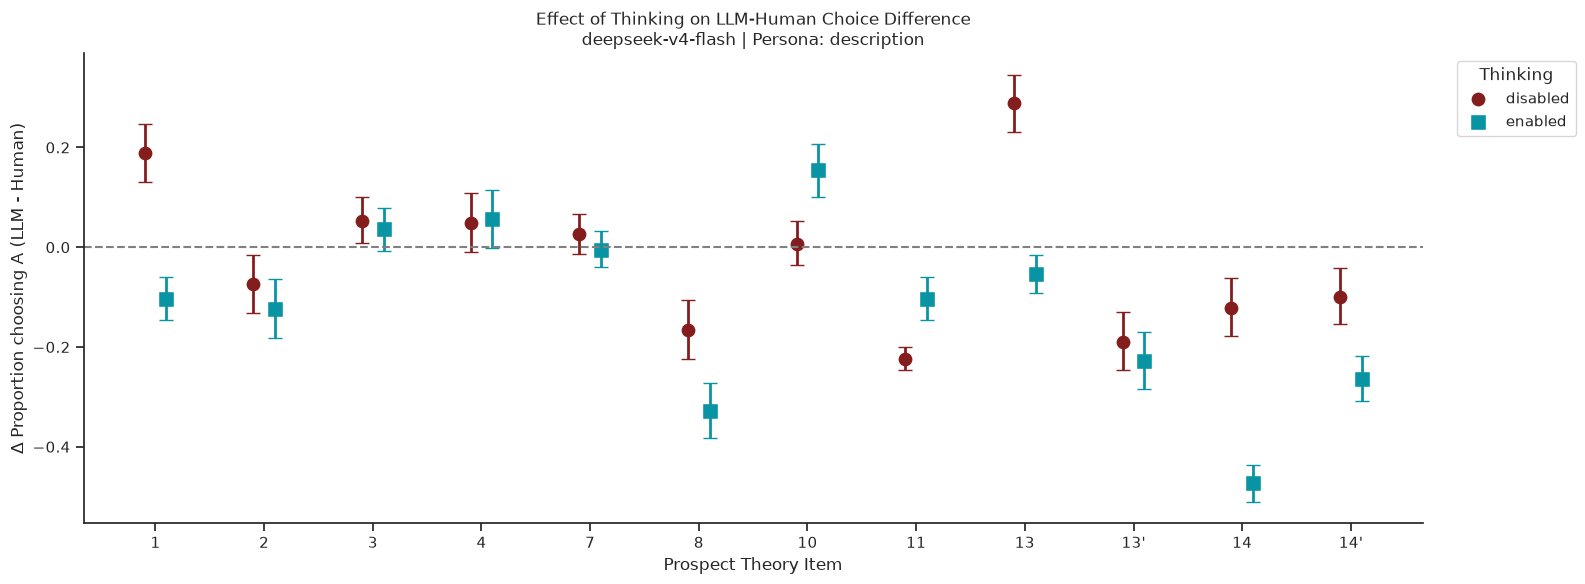

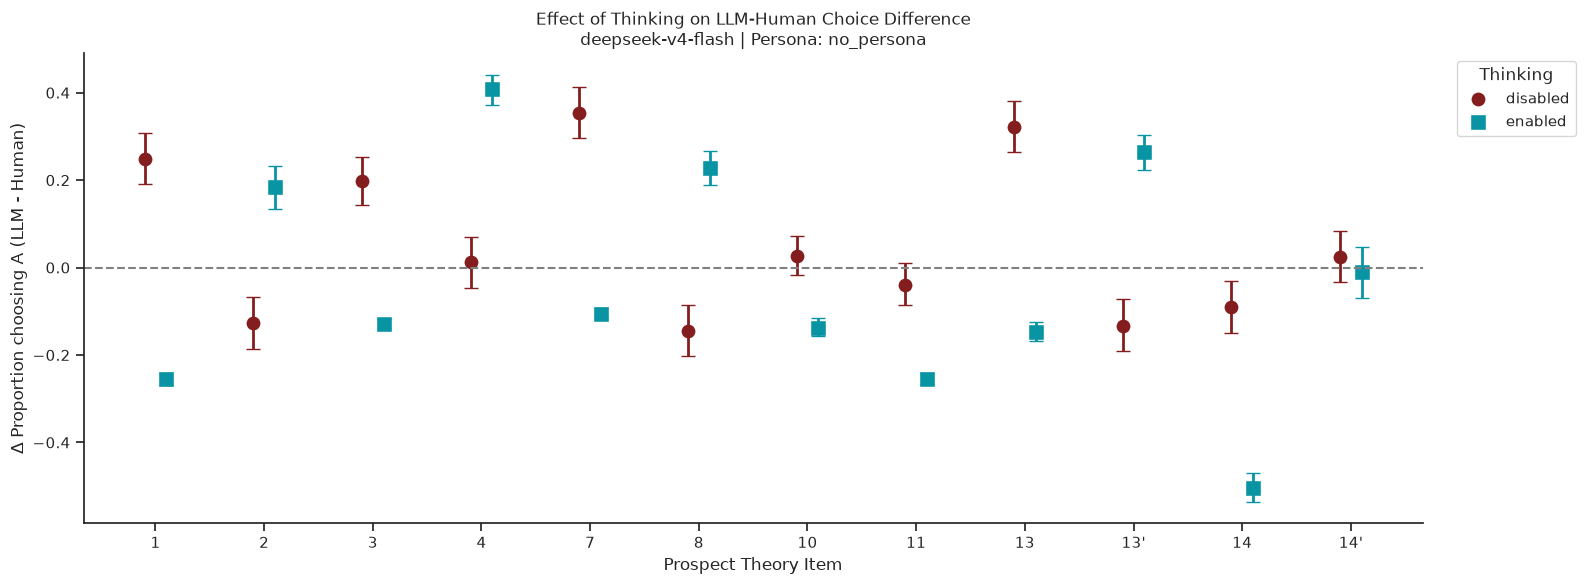

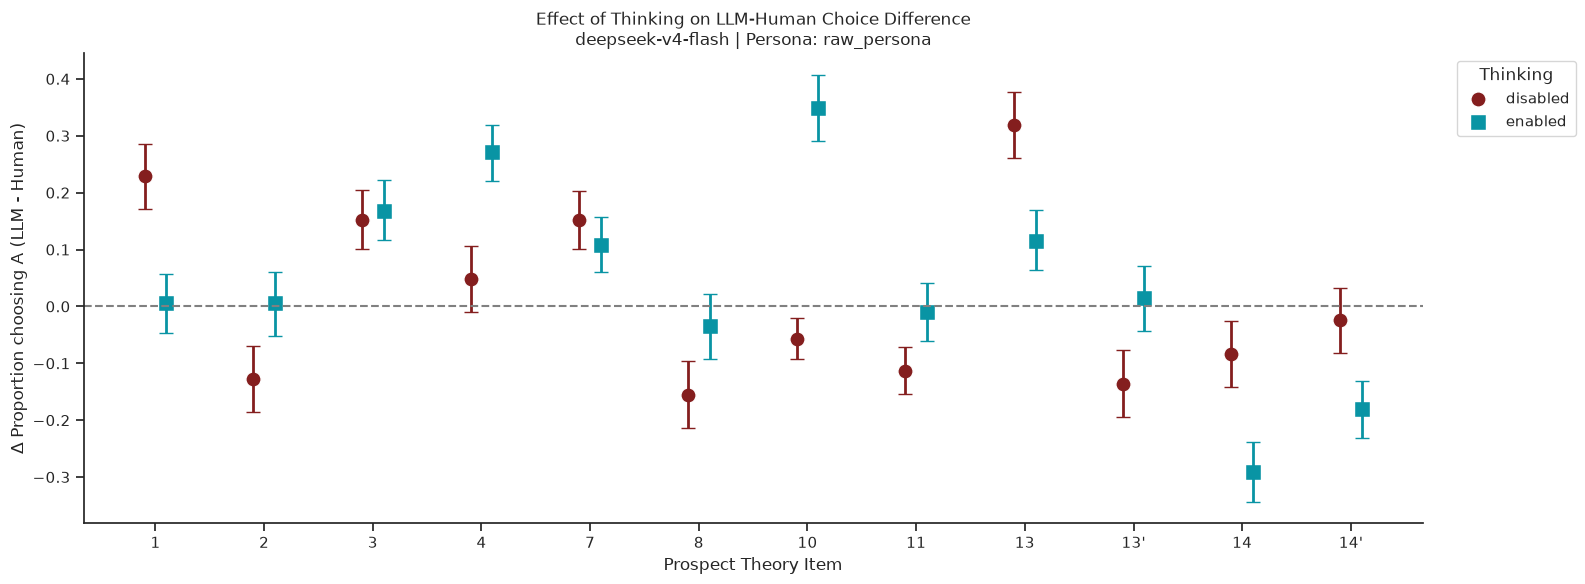

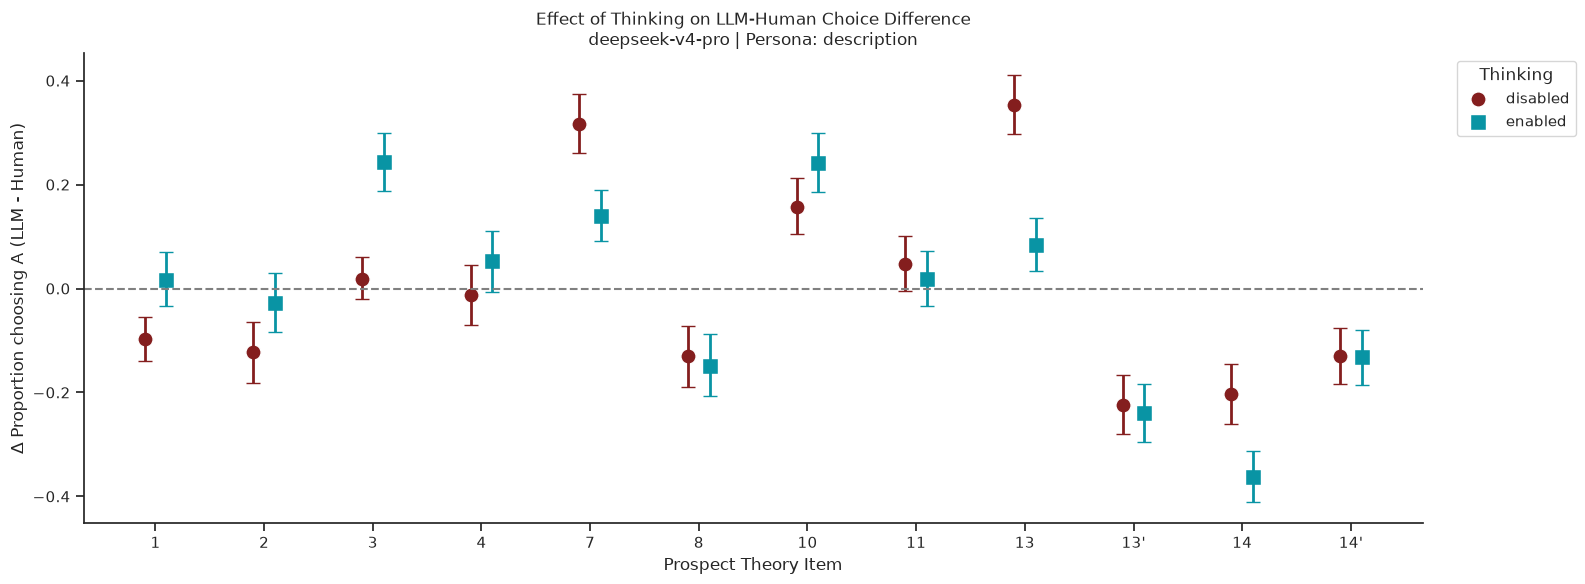

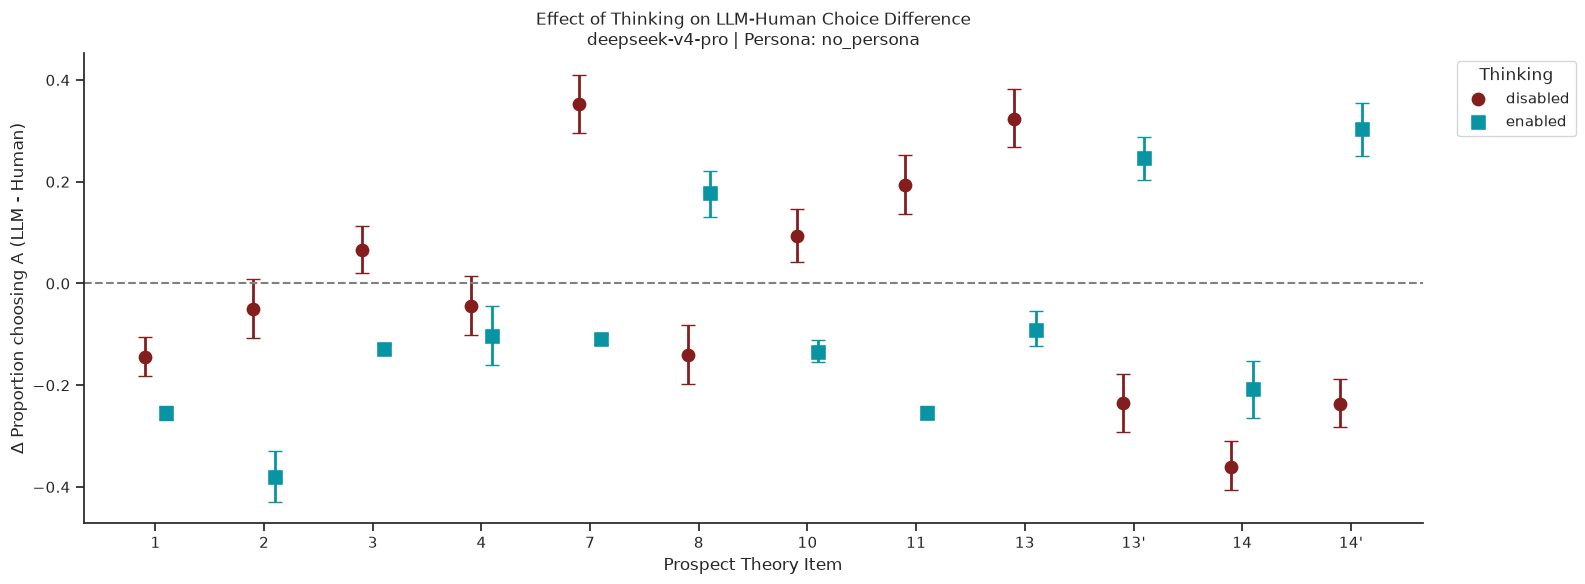

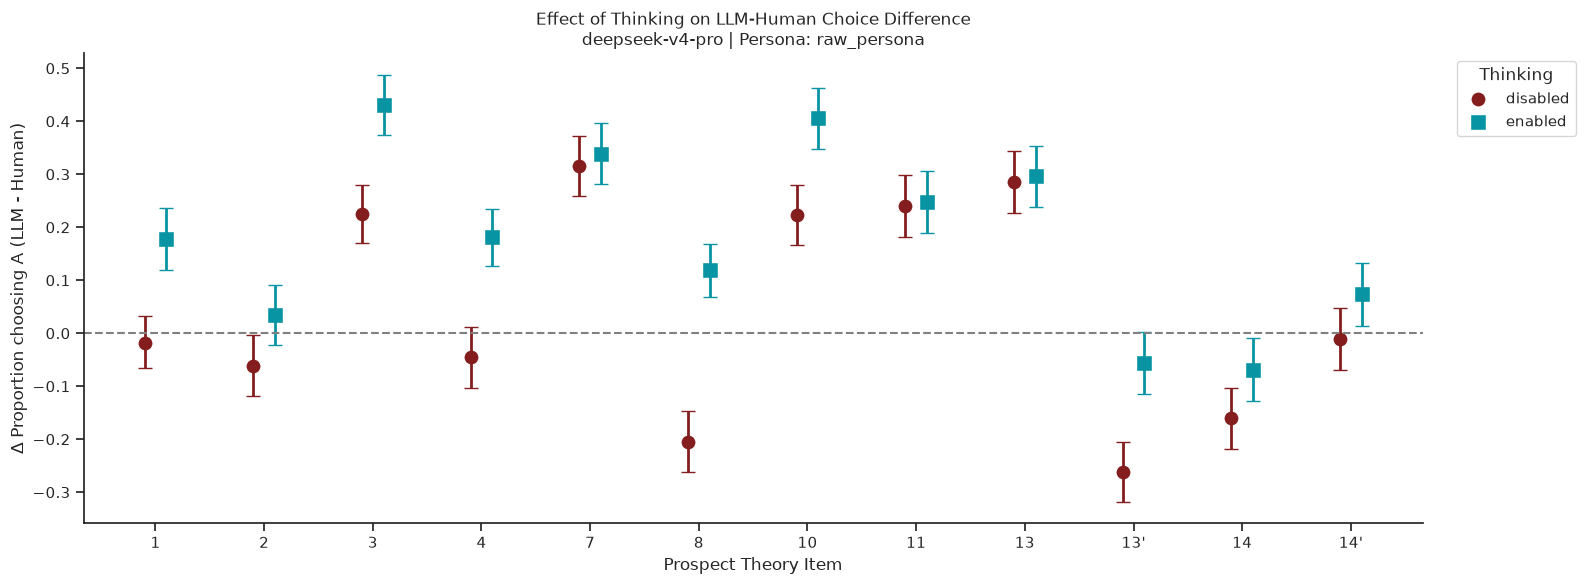

In [20]:
sns.set_theme(font_scale=1, style="ticks")

thinking_markers = {
    "disabled": "o",
    "enabled": "s"
}

thinking_colors = {
    "disabled": "#841E1E",
    "enabled": "#0994a4"
}

thinking_offsets = {
    "disabled": -0.10,
    "enabled": 0.10
}


for (llm, persona), group_df in delta_summary.groupby(
    ["llm", "persona"]
):

    fig, ax = plt.subplots(figsize=(16, 6))

    for thinking, thinking_df in group_df.groupby("thinking"):

        thinking_df = thinking_df.copy()
        thinking_df["x_pos"] = (
            thinking_df["question"].map(item_to_x)
            + thinking_offsets[thinking]
        )

        thinking_df = thinking_df.sort_values("x_pos")

        ax.scatter(
            thinking_df["x_pos"],
            thinking_df["delta"],
            marker=thinking_markers[thinking],
            s=120,
            color=thinking_colors[thinking],
            edgecolor="white",
            linewidth=1,
            label=thinking
        )

        ax.errorbar(
            thinking_df["x_pos"],
            thinking_df["delta"],
            yerr=[
                thinking_df["delta"] - thinking_df["lower_95CI"],
                thinking_df["upper_95CI"] - thinking_df["delta"]
            ],
            fmt="none",
            ecolor=thinking_colors[thinking],
            elinewidth=2,
            capsize=5,
        )

    ax.axhline(
        y=0,
        linestyle="--",
        color="grey",
        linewidth=1.5
    )

    ax.set_xticks(range(len(item_order)))
    ax.set_xticklabels(item_order)

    ax.set_xlabel("Prospect Theory Item")
    ax.set_ylabel("∆ Proportion choosing A (LLM - Human)")

    ax.set_title(
        f"Effect of Thinking on LLM-Human Choice Difference\n"
        f"{llm} | Persona: {persona}"
    )

    ax.legend(
        title="Thinking",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    sns.despine()
    plt.tight_layout()
    plt.show()

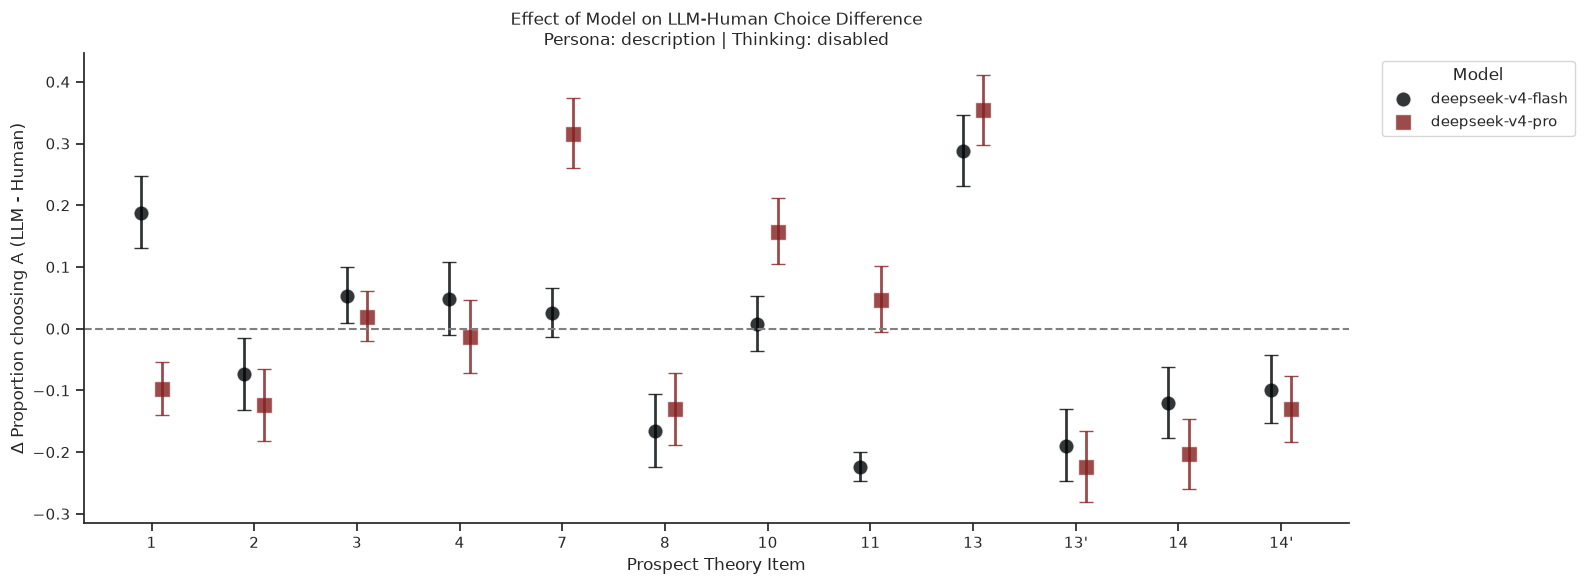

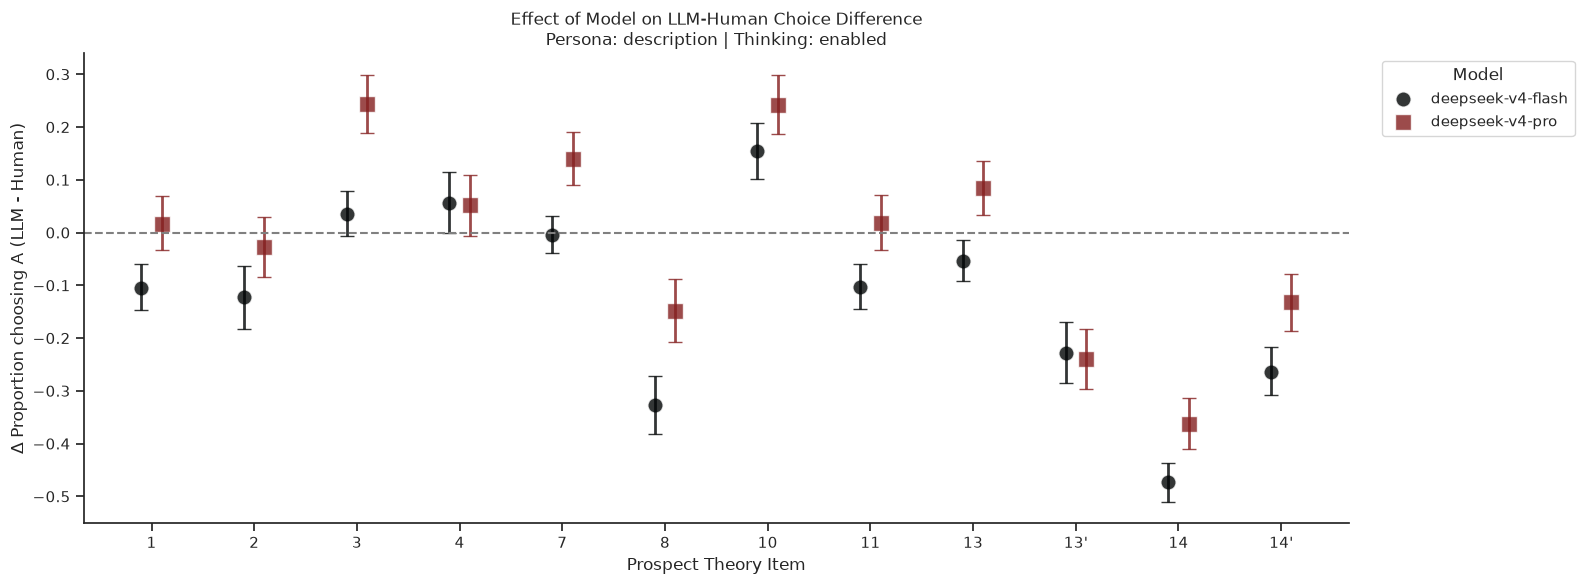

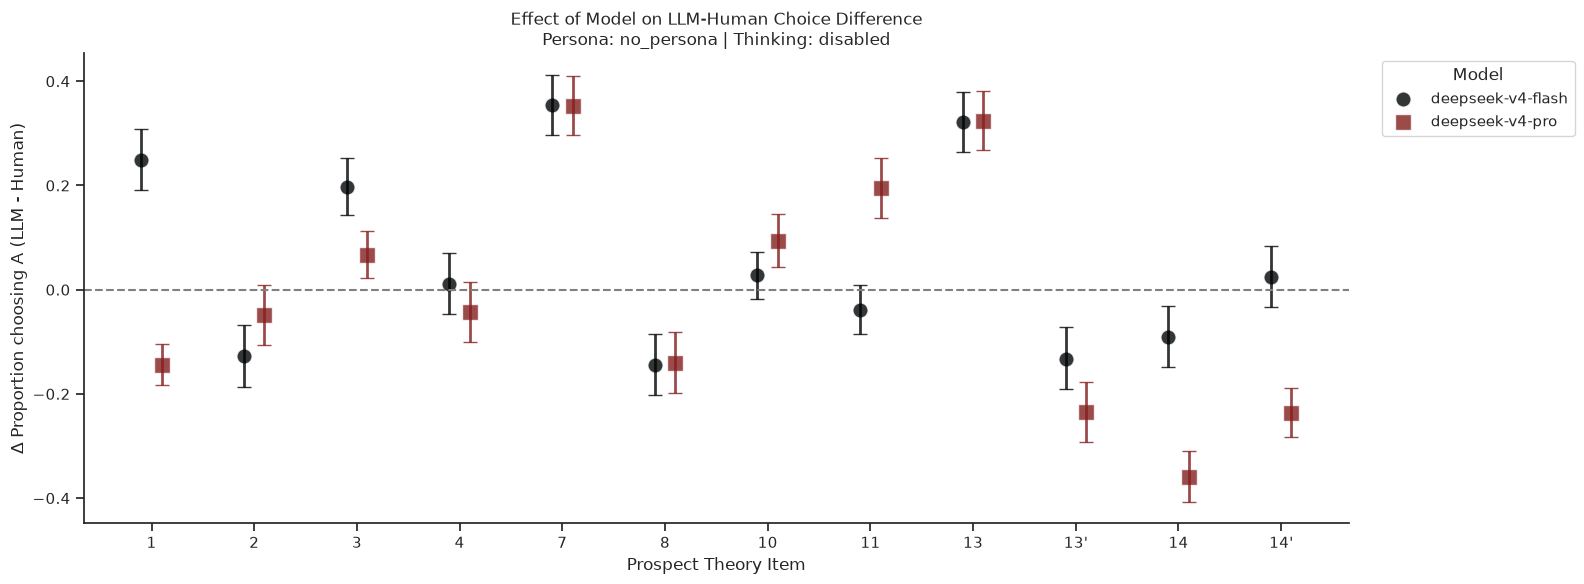

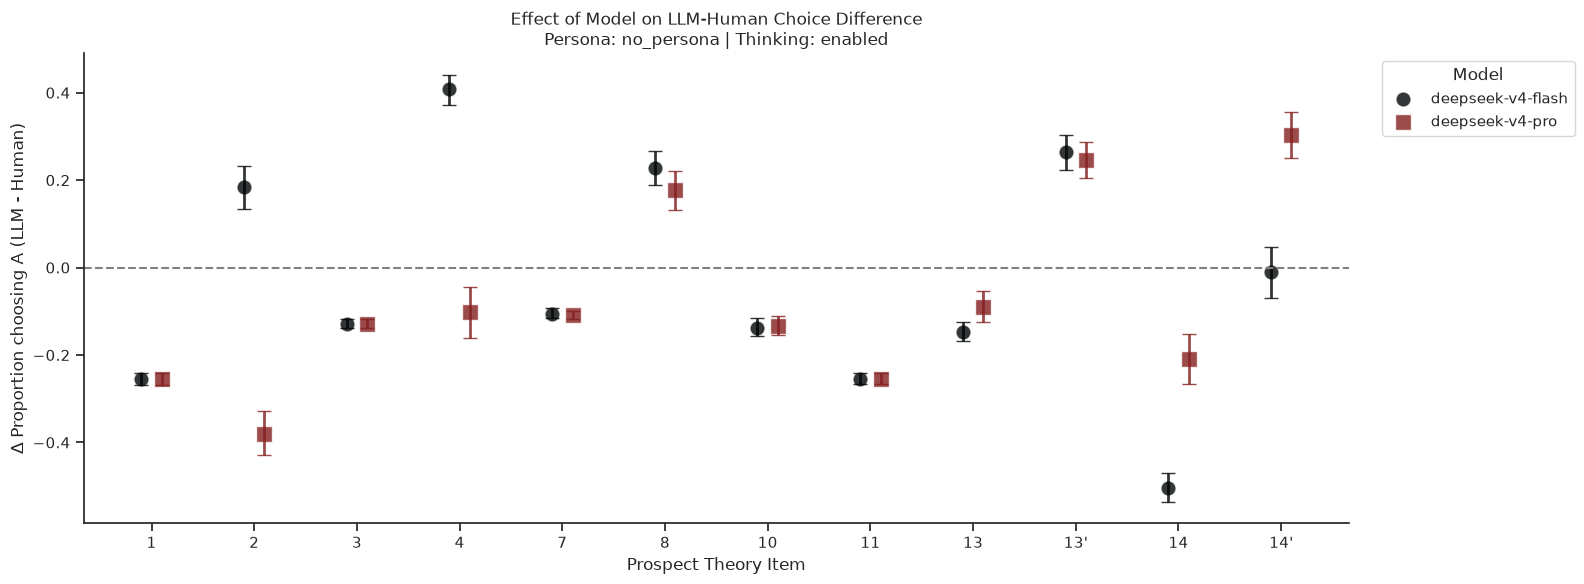

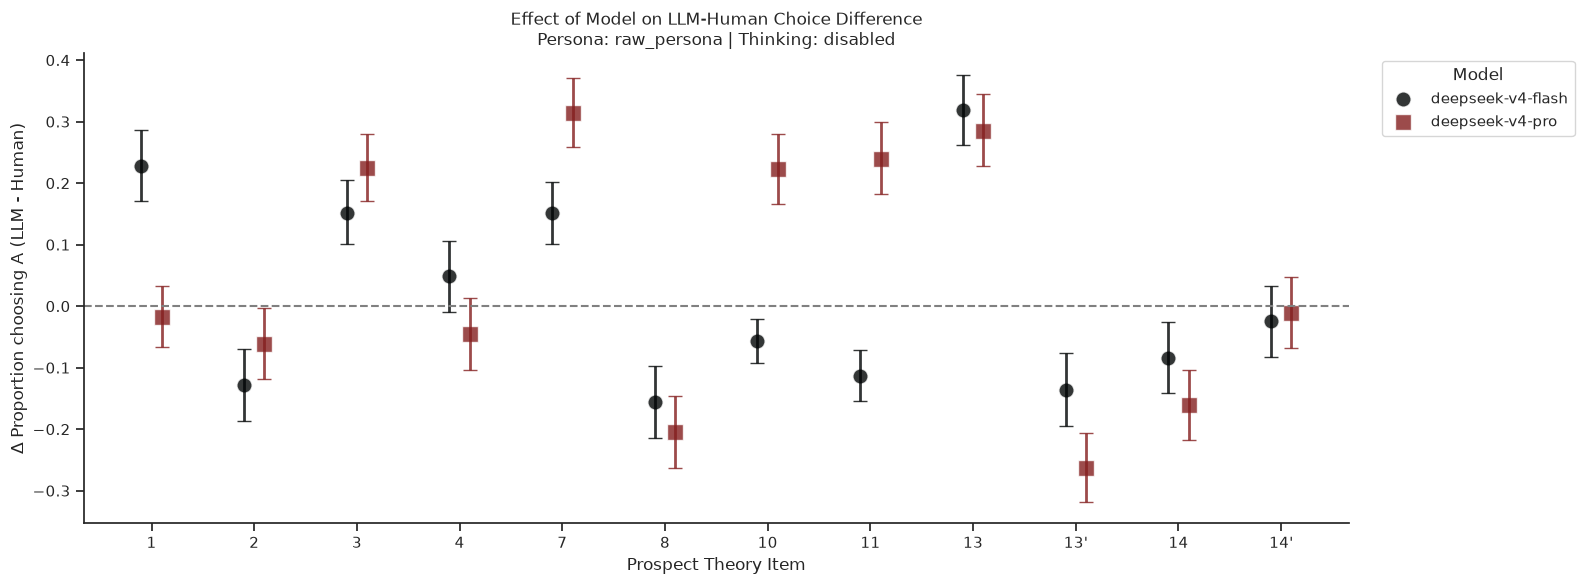

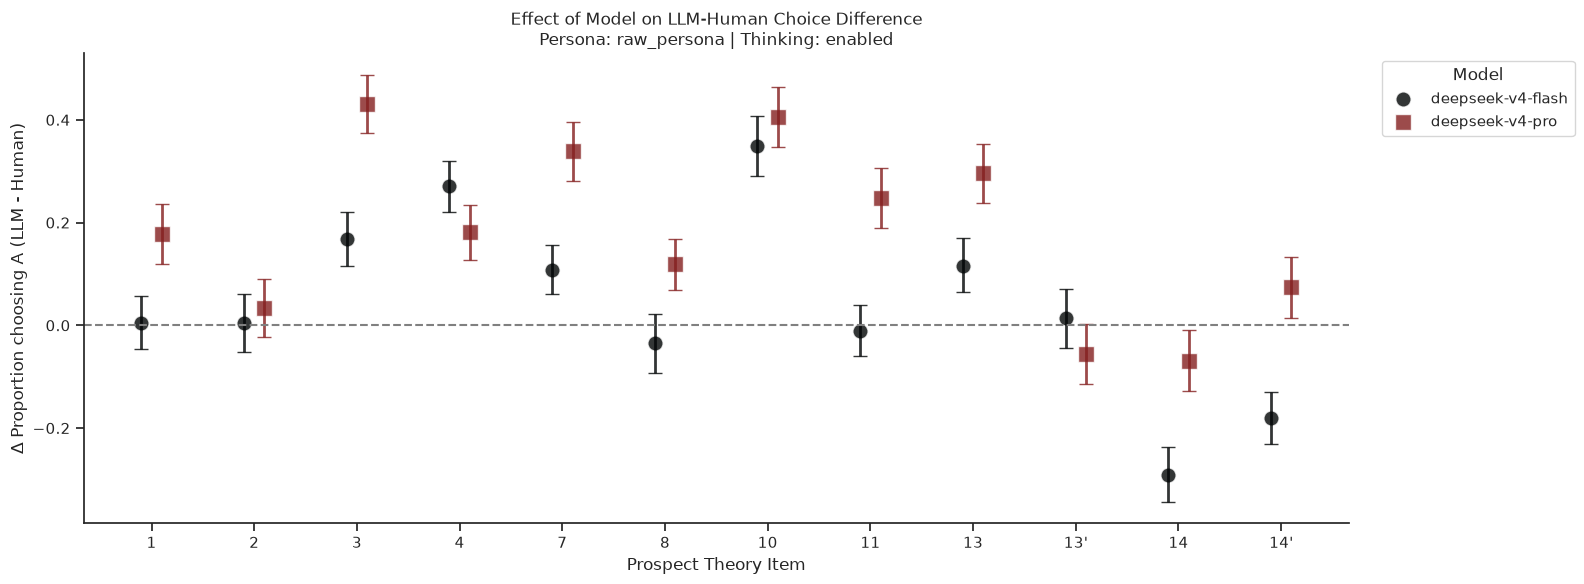

In [21]:
sns.set_theme(font_scale=1, style="ticks")

llm_markers = {
    "deepseek-v4-flash": "o",
    "deepseek-v4-pro": "s"
}

llm_colors = {
    "deepseek-v4-flash": "#000304",
    "deepseek-v4-pro": "#841E1E"
}

llm_offsets = {
    "deepseek-v4-flash": -0.10,
    "deepseek-v4-pro": 0.10
}


for (persona, thinking), group_df in delta_summary.groupby(
    ["persona", "thinking"]
):

    fig, ax = plt.subplots(figsize=(16, 6))

    for llm, llm_df in group_df.groupby("llm"):

        llm_df = llm_df.copy()

        llm_df["x_pos"] = (
            llm_df["question"].map(item_to_x)
            + llm_offsets[llm]
        )

        llm_df = llm_df.sort_values("x_pos")

        ax.scatter(
            llm_df["x_pos"],
            llm_df["delta"],
            marker=llm_markers[llm],
            s=120,
            color=llm_colors[llm],
            alpha=0.8,
            edgecolor="white",
            linewidth=1,
            label=llm
        )

        ax.errorbar(
            llm_df["x_pos"],
            llm_df["delta"],
            yerr=[
                llm_df["delta"] - llm_df["lower_95CI"],
                llm_df["upper_95CI"] - llm_df["delta"]
            ],
            fmt="none",
            ecolor=llm_colors[llm],
            elinewidth=2,
            capsize=5,
            alpha=0.8
        )

    ax.axhline(
        y=0,
        linestyle="--",
        color="grey",
        linewidth=1.5
    )

    ax.set_xticks(range(len(item_order)))
    ax.set_xticklabels(item_order)

    ax.set_xlabel("Prospect Theory Item")
    ax.set_ylabel("∆ Proportion choosing A (LLM - Human)")

    ax.set_title(
        f"Effect of Model on LLM-Human Choice Difference\n"
        f"Persona: {persona} | Thinking: {thinking}"
    )

    ax.legend(
        title="Model",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    sns.despine()
    plt.tight_layout()

In [22]:
observed_mae = (
    delta_summary
    .assign(absolute_error=lambda x: x["delta"].abs())
    .groupby(["llm", "persona", "thinking"])["absolute_error"]
    .mean()
    .reset_index(name="MAE")
)

mae_bootstrap = (
    bootstrap_delta
    .groupby(["llm", "persona", "thinking", "bootstrap"])["absolute_error"]
    .mean()
    .reset_index(name="MAE")
)

bootstrap_ci = (
    mae_bootstrap
    .groupby(["llm", "persona", "thinking"])["MAE"]
    .agg(
        MAE_lower_95CI=lambda x: x.quantile(0.025),
        MAE_upper_95CI=lambda x: x.quantile(0.975)
    )
    .reset_index()
)


mae_summary = observed_mae.merge(bootstrap_ci, on=["llm", "persona", "thinking"])

mae_summary

,llm,persona,thinking,MAE,MAE_lower_95CI,MAE_upper_95CI
0,deepseek-v4-flash,description,disabled,0.123639,0.113392,0.136653
1,deepseek-v4-flash,description,enabled,0.160695,0.145338,0.179475
2,deepseek-v4-flash,no_persona,disabled,0.143507,0.137232,0.154908
3,deepseek-v4-flash,no_persona,enabled,0.218741,0.211932,0.228551
4,deepseek-v4-flash,raw_persona,disabled,0.133077,0.123769,0.144706
5,deepseek-v4-flash,raw_persona,enabled,0.129604,0.121928,0.151057
6,deepseek-v4-pro,description,disabled,0.151205,0.139753,0.165967
7,deepseek-v4-pro,description,enabled,0.142304,0.132302,0.158484
8,deepseek-v4-pro,no_persona,disabled,0.186601,0.172792,0.200860
9,deepseek-v4-pro,no_persona,enabled,0.198947,0.187816,0.209899


In [23]:
# Random baseline MAE for each bootstrap replicate
random_mae_bootstrap = (
    bootstrap_delta
    .assign(
        random_absolute_error=lambda x: (
            x["A_p_random"] - x["A_p_human"]
        ).abs()
    )
    .groupby(
        ["llm", "persona", "thinking", "bootstrap"]
    )["random_absolute_error"]
    .mean()
    .reset_index(name="random_MAE")
)

random_mae_ci = (
    random_mae_bootstrap["random_MAE"]
    .agg(
        mean="mean",
        lower_95CI=lambda x: x.quantile(0.025),
        upper_95CI=lambda x: x.quantile(0.975)
    )
)

random_mae = random_mae_ci["mean"]
random_lower = random_mae_ci["lower_95CI"]
random_upper = random_mae_ci["upper_95CI"]

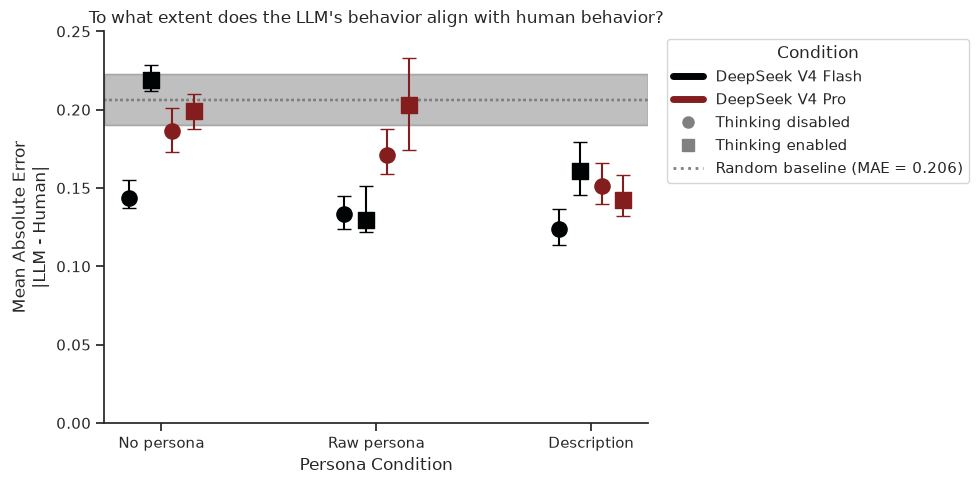

In [24]:
sns.set_theme(font_scale=1, style="ticks")
#chance_mae = (human_obs["p_human"] - 0.5).abs().mean()

persona_order = [
    "no_persona",
    "raw_persona",
    "description"
]

persona_labels = {
    "no_persona": "No persona",
    "raw_persona": "Raw persona",
    "description": "Description"
}

# Model = color
llm_colors = {
    "deepseek-v4-flash": "#000304",
    "deepseek-v4-pro": "#841E1E"
}

llm_labels = {
    "deepseek-v4-flash": "DeepSeek V4 Flash",
    "deepseek-v4-pro": "DeepSeek V4 Pro"
}

# Thinking = marker
thinking_markers = {
    "disabled": "o",
    "enabled": "s"
}

thinking_labels = {
    "disabled": "Thinking disabled",
    "enabled": "Thinking enabled"
}

# Horizontal offsets
condition_offsets = {
    ("deepseek-v4-flash", "disabled"): -0.15,
    ("deepseek-v4-flash", "enabled"): -0.05,
    ("deepseek-v4-pro", "disabled"): 0.05,
    ("deepseek-v4-pro", "enabled"): 0.15
}


plot_df = mae_summary.copy()

# numeric position for each persona
persona_to_x = {
    "no_persona": 0,
    "raw_persona": 1,
    "description": 2
}

plot_df["base_x"] = plot_df["persona"].map(persona_to_x).astype(float)
plot_df["offset"] = plot_df.apply(
    lambda row: condition_offsets[
        (row["llm"], row["thinking"])
    ],
    axis=1
)

plot_df["x_pos"] = (plot_df["base_x"] + plot_df["offset"])
fig, ax = plt.subplots(figsize=(10, 5))
for _, row in plot_df.iterrows():

    color = llm_colors[row["llm"]]
    marker = thinking_markers[row["thinking"]]

    # 95% CI
    ax.errorbar(
        row["x_pos"],
        row["MAE"],
        yerr=[
            [row["MAE"] - row["MAE_lower_95CI"]],
            [row["MAE_upper_95CI"] - row["MAE"]]
        ],
        fmt="none",
        ecolor=color,
        elinewidth=1.5,
        capsize=5,
        zorder=2
    )


    # Point estimate
    ax.scatter(
        row["x_pos"],
        row["MAE"],
        marker=marker,
        s=120,
        color=color,
        linewidth=1,
        zorder=2
    )

    # Random baseline
    ax.axhline(
        y=random_mae,
        linestyle=":",
        color="grey",
        linewidth=1.5,
        alpha=0.8,
        zorder=0
    )

    # 95% bootstrap CI
    ax.axhspan(
        random_lower,
        random_upper,
        color="grey",
        alpha=0.05,
        zorder=1
    )


# Chance baseline
# ax.axhline(
#     y=chance_mae,
#     linestyle=":",
#     color="black",
#     linewidth=1.5,
#     label=f"Chance baseline (MAE = {chance_mae:.3f})"
# )
ax.set_xticks(range(len(persona_order)))
ax.set_xticklabels([persona_labels[p]for p in persona_order])
ax.set_xlabel("Persona Condition")
ax.set_ylabel("Mean Absolute Error\n|LLM - Human|")
ax.set_ylim(0, 0.25)
ax.set_title("To what extent does the LLM's behavior align with human behavior?")
from matplotlib.lines import Line2D
legend_handles = [

    # Models: COLOR
    Line2D(
        [],
        [],
        color="#000304",
        linewidth=5,
        label="DeepSeek V4 Flash"
    ),

    Line2D(
        [],
        [],
        color="#841E1E",
        linewidth=5,
        label="DeepSeek V4 Pro"
    ),

    # Thinking: MARKER
    Line2D(
        [],
        [],
        linestyle="none",
        marker="o",
        markersize=8,
        color="grey",
        label="Thinking disabled"
    ),

    Line2D(
        [],
        [],
        linestyle="none",
        marker="s",
        markersize=8,
        color="grey",
        label="Thinking enabled"
    ),

    Line2D(
    [],
    [],
    color="grey",
    linestyle=":",
    linewidth=2,
    label=f"Random baseline (MAE = {random_mae:.3f})"
)
]

ax.legend(
    handles=legend_handles,
    title="Condition",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

sns.despine()
plt.tight_layout()

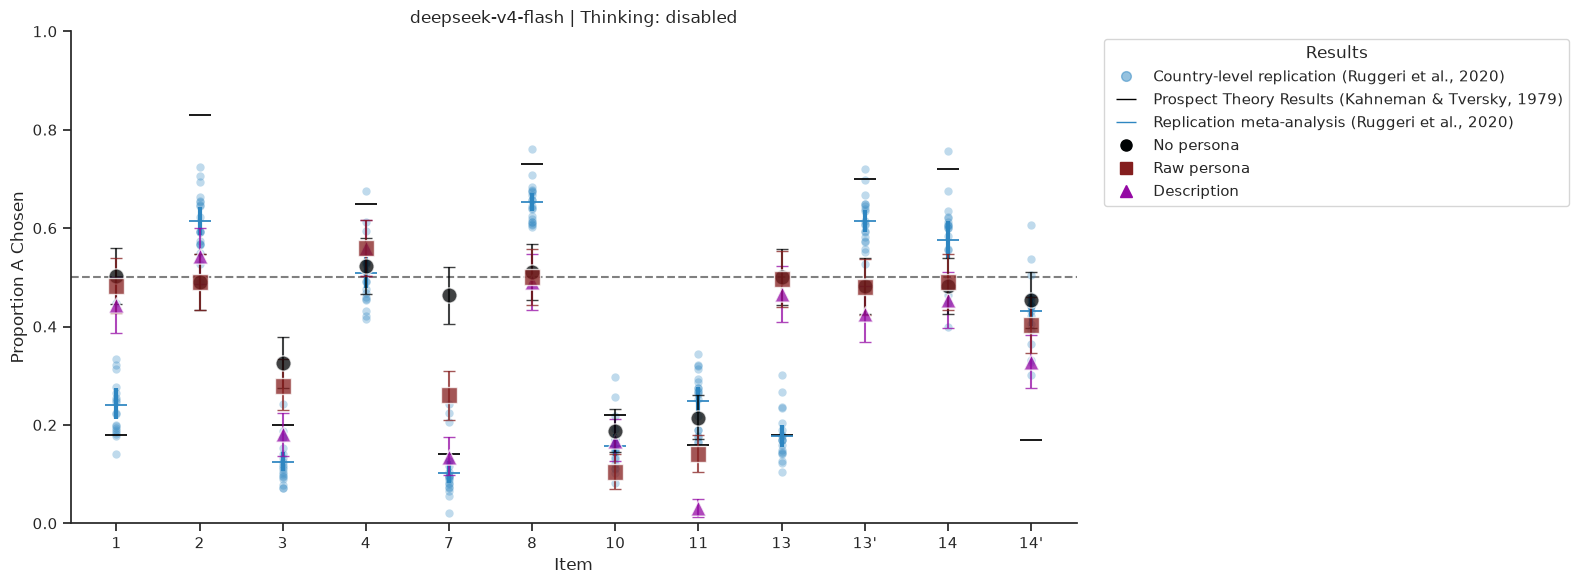

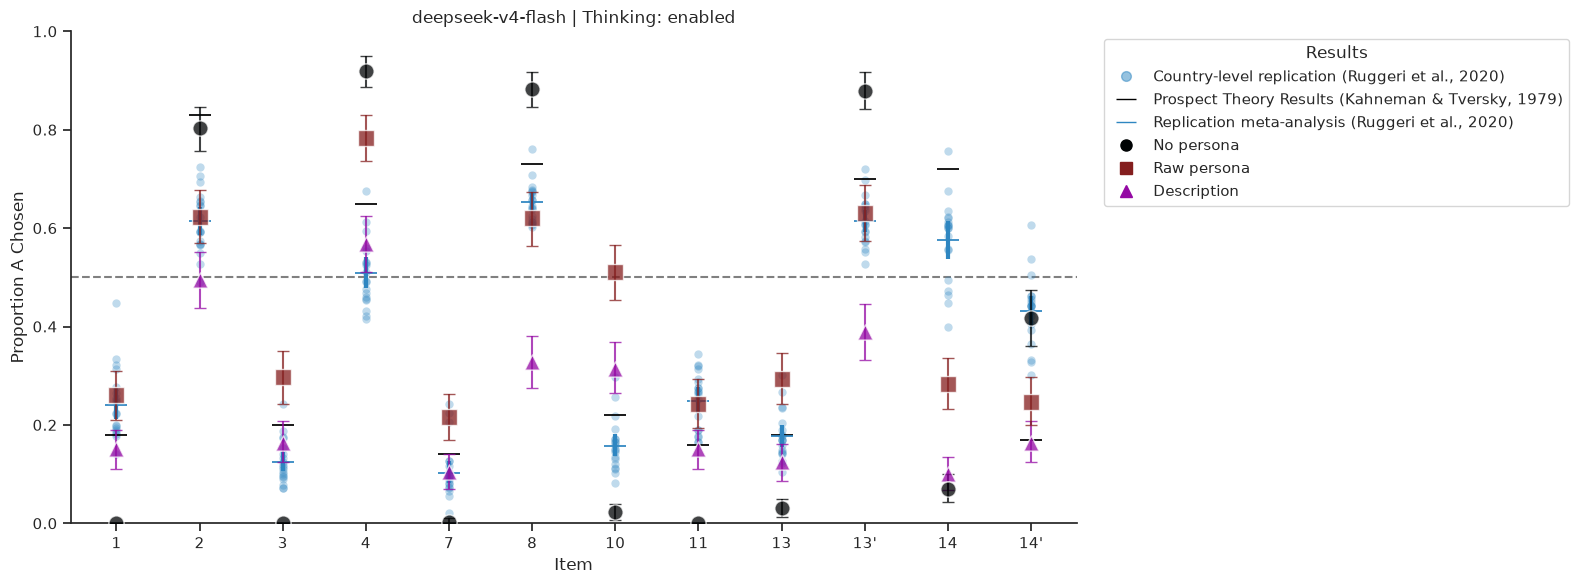

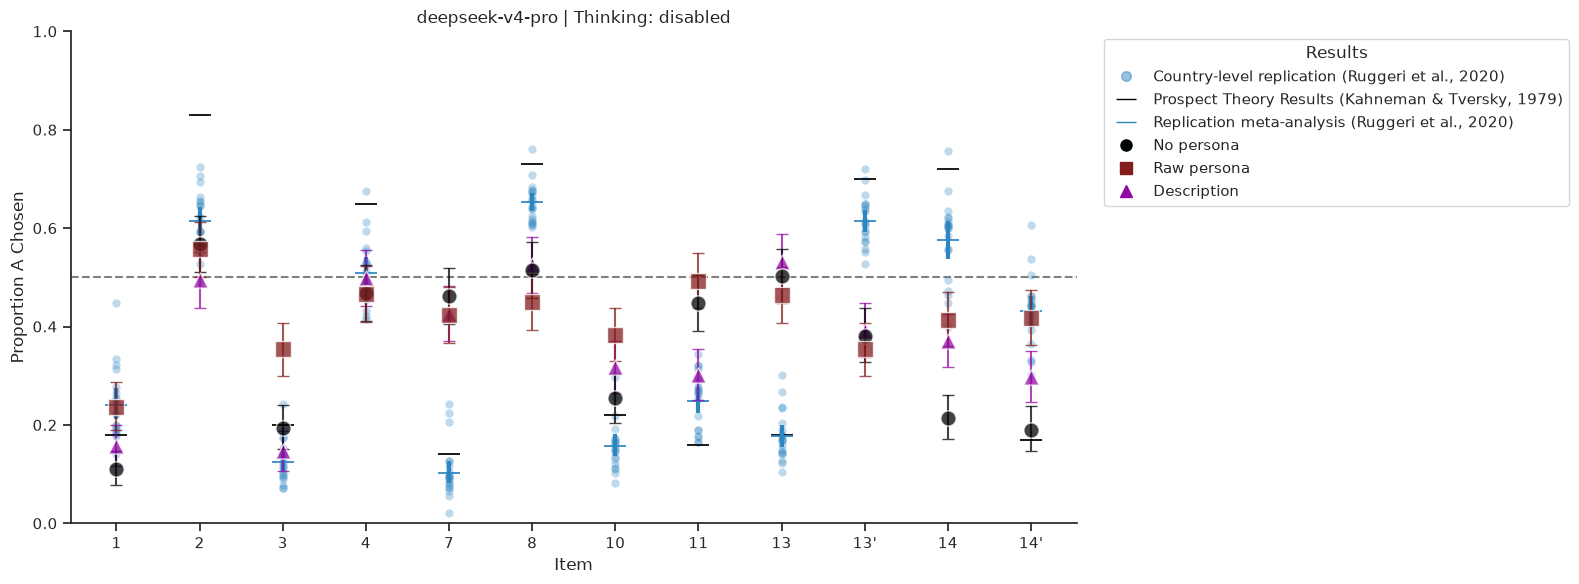

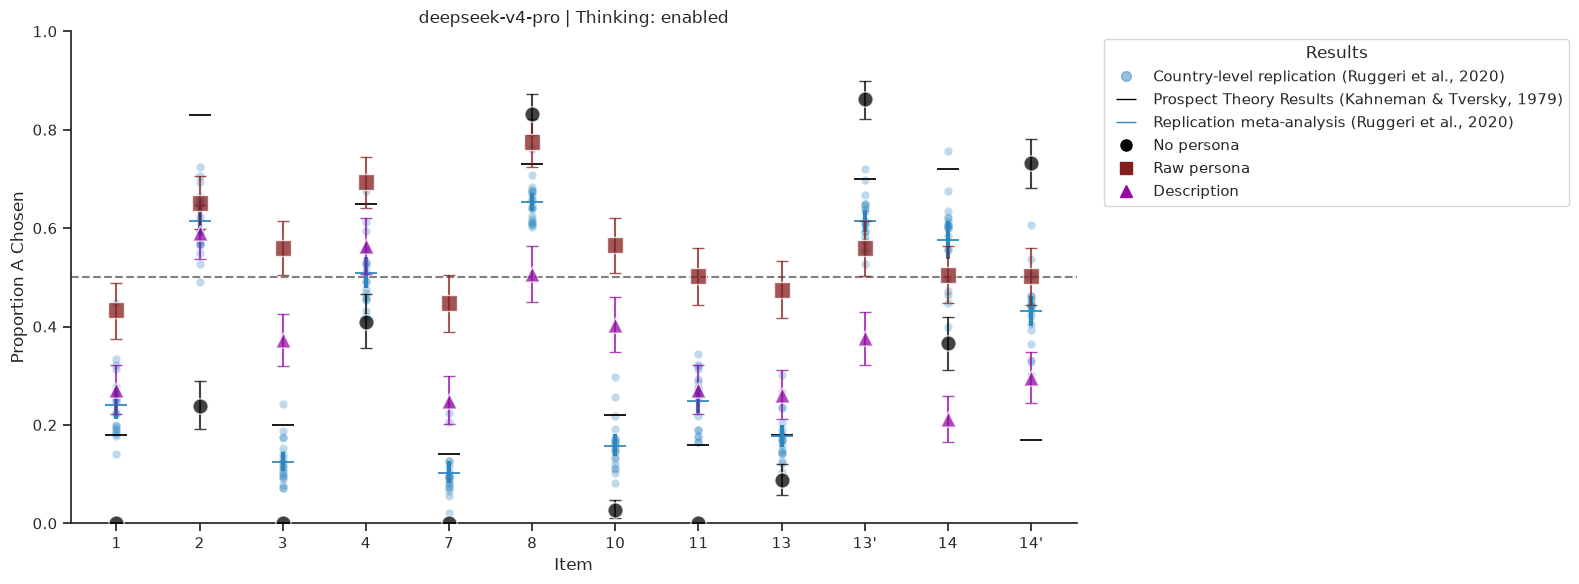

In [25]:
sns.set_theme(font_scale=1, style="ticks")

persona_markers = {
    "no_persona": "o",
    "raw_persona": "s",
    "description": "^"
}

persona_colors = {
    "no_persona": "#000304",
    "raw_persona": "#841E1E",
    "description": "#9409a4"
}


# LLM 95% CIs
llm_prop_ci = (
    bootstrap_delta
    .groupby(
        ["llm", "persona", "thinking", "question"]
    )["A_p_llm"]
    .agg(
        lower_95CI=lambda x: x.quantile(0.025),
        upper_95CI=lambda x: x.quantile(0.975)
    )
    .reset_index()
)

results = results.copy()
results["question"] = (
    results["question"]
    .astype(str)
    .str.replace("Loss_Aversion_", "", regex=False)
    .str.replace("_inverse", "'", regex=False)
)

results = results.merge(
    llm_prop_ci,
    on=["llm", "persona", "thinking", "question"],
    how="left"
)


for (llm, thinking), group_df in results.groupby(
    ["llm", "thinking"]
):

    fig, ax = plt.subplots(figsize=(16, 6))


    # COUNTRY-LEVEL REPLICATION DATA
    sns.scatterplot(
        x="x_pos",
        y="Proportion",
        data=long_data,
        linewidth=0,
        alpha=0.3,
        color="#2e86c1",
        markers="o",
        ax=ax,
        zorder=1,
        legend=False
    )


    # ORIGINAL KAHNEMAN & TVERSKY
    sns.scatterplot(
        data=original_pt_proportions_df,
        x="x_pos",
        y="Proportion",
        marker="_",
        s=250,
        color="black",
        ax=ax,
        zorder=2,
        legend=False
    )


    # REPLICATION META-ANALYSIS
    sns.scatterplot(
        data=prop_df,
        x="x_pos",
        y="prop",
        marker="_",
        s=250,
        color="#2e86c1",
        ax=ax,
        zorder=4,
        legend=False
    )


    # META-ANALYSIS ERROR BARS
    for _, row in prop_df.dropna(subset=["x_pos"]).iterrows():

        x = int(row["x_pos"])

        lower_error = row["prop"] - row["lb"]
        upper_error = row["ub"] - row["prop"]

        ax.errorbar(
            x,
            row["prop"],
            yerr=[
                [lower_error],
                [upper_error]
            ],
            linestyle="",
            linewidth=3,
            color="#2e86c1",
            capsize=0,
            zorder=3
        )


    # LLM REPLICATION RESULTS + 95% CI
    for persona, persona_df in group_df.groupby("persona"):

        for _, row in persona_df.iterrows():

            color = persona_colors.get(
                row["persona"],
                "black"
            )

            marker = persona_markers.get(
                row["persona"],
                "o"
            )

            # 95% CI
            lower_error = (
                row["A_proportion"]
                - row["lower_95CI"]
            )

            upper_error = (
                row["upper_95CI"]
                - row["A_proportion"]
            )

            ax.errorbar(
                row["x_pos"],
                row["A_proportion"],
                yerr=[
                    [lower_error],
                    [upper_error]
                ],
                fmt="none",
                color=color,
                elinewidth=1.5,
                capsize=4,
                alpha=0.75,
                zorder=6
            )

            # Point estimate
            ax.scatter(
                row["x_pos"],
                row["A_proportion"],
                marker=marker,
                s=120,
                color=color,
                edgecolor="white",
                linewidth=1,
                alpha=0.75,
                zorder=7
            )


    # INDIFFERENCE LINE
    ax.axhline(
        y=0.5,
        linestyle="--",
        color="grey",
        zorder=0
    )


    # AXES
    ax.set_xticks(range(len(item_order)))
    ax.set_xticklabels(item_order)

    ax.set_xlabel("Item")
    ax.set_ylabel("Proportion A Chosen")

    ax.set_ylim(0, 1)

    ax.set_title(
        f"{llm} | Thinking: {thinking}"
    )


    # LEGEND
    from matplotlib.lines import Line2D

    handles = [
        Line2D(
            [],
            [],
            marker="o",
            color="#2e86c1",
            linestyle="none",
            markersize=7,
            alpha=0.5,
            label="Country-level replication (Ruggeri et al., 2020)"
        ),

        Line2D(
            [],
            [],
            marker="_",
            color="black",
            linestyle="none",
            markersize=14,
            label="Prospect Theory Results (Kahneman & Tversky, 1979)"
        ),

        Line2D(
            [],
            [],
            marker="_",
            color="#2e86c1",
            linestyle="none",
            markersize=14,
            label="Replication meta-analysis (Ruggeri et al., 2020)"
        ),

        Line2D(
            [],
            [],
            marker="o",
            color="#000304",
            linestyle="none",
            markersize=8,
            label="No persona"
        ),

        Line2D(
            [],
            [],
            marker="s",
            color="#841E1E",
            linestyle="none",
            markersize=8,
            label="Raw persona"
        ),

        Line2D(
            [],
            [],
            marker="^",
            color="#9409a4",
            linestyle="none",
            markersize=8,
            label="Description"
        ),
    ]


    ax.legend(
        handles=handles,
        title="Results",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    sns.despine()
    plt.tight_layout()

RQ1: Compare LLM responses MAE to random baseline response & compute directional consistency for the responses

In [ ]:
# Chance baseline: a responder that ignores the options (p = 0.5).
chance_mae = (human_obs["p_human"] - 0.5).abs().mean()

analysis_rows = []
for (llm, persona, thinking), group in delta_summary.groupby(["llm", "persona", "thinking"]):
    # Direction consistency: same side of 0.5 as humans on each item.
    same_direction = (np.sign(group["p_llm"] - 0.5) == np.sign(group["p_human"] - 0.5)).mean()
    analysis_rows.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,     
        "direction_consistency": same_direction
    })

analysis_summary = pd.DataFrame(analysis_rows)
# Overall position bias per condition (from the cell-7 loop).
analysis_summary = analysis_summary.merge(position_bias_summary, on=["llm", "persona", "thinking"])
# Add observed MAE and its bootstrap 95% CI
analysis_summary = analysis_summary.merge(mae_summary,on=["llm", "persona", "thinking"])
# Difference between chance performance and observed MAE.
# Positive values indicate lower MAE than chance.
analysis_summary["MAE_improvement_over_chance"] = (chance_mae - analysis_summary["MAE"])

# Determine whether the entire 95% CI for MAE lies below the chance baseline.
# analysis_summary["MAE_below_chance_baseline"] = (analysis_summary["MAE_upper_95CI"] < chance_mae)
analysis_summary.round(3)

,llm,persona,thinking,direction_consistency,position_bias,position_bias_lower_95CI,position_bias_upper_95CI,position_bias_significant,MAE,MAE_lower_95CI,MAE_upper_95CI,MAE_improvement_over_chance
0,deepseek-v4-flash,description,disabled,0.750,0.553,0.528,0.577,True,0.124,0.113,0.137,0.082
1,deepseek-v4-flash,description,enabled,0.667,-0.056,-0.122,0.008,False,0.161,0.145,0.179,0.045
2,deepseek-v4-flash,no_persona,disabled,0.583,0.774,0.758,0.790,True,0.144,0.137,0.155,0.062
3,deepseek-v4-flash,no_persona,enabled,0.917,0.001,-0.017,0.018,False,0.219,0.212,0.229,-0.014
4,deepseek-v4-flash,raw_persona,disabled,0.667,0.720,0.702,0.738,True,0.133,0.124,0.145,0.072
5,deepseek-v4-flash,raw_persona,enabled,0.833,-0.037,-0.106,0.033,False,0.130,0.122,0.151,0.076
6,deepseek-v4-pro,description,disabled,0.583,-0.340,-0.373,-0.308,True,0.151,0.140,0.166,0.054
7,deepseek-v4-pro,description,enabled,0.833,-0.007,-0.087,0.074,False,0.142,0.132,0.158,0.063
8,deepseek-v4-pro,no_persona,disabled,0.667,-0.299,-0.327,-0.272,True,0.187,0.173,0.201,0.019
9,deepseek-v4-pro,no_persona,enabled,0.667,0.066,0.045,0.086,True,0.199,0.188,0.210,0.006


Check if it makes sense to combine these items:

In [ ]:
loss_cols = [
    "Loss_Aversion_1",
    "Loss_Aversion_3",
    "Loss_Aversion_5",
    "Loss_Aversion_7",
    "Loss_Aversion_9",
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13"
]

alpha_results = []

for (llm, persona, thinking), group in df.groupby(["llm", "persona", "thinking"]):

    items = group[loss_cols].replace({
        "A": 0,
        "B": 1
    }).astype(float)

    # Overall alpha
    overall_alpha = pg.cronbach_alpha(items)[0]

    result = {
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "cronbach_alpha": overall_alpha
    }

    # Alpha if each item is removed
    for item in loss_cols:
        items_without = items.drop(columns=item)
        alpha_without = pg.cronbach_alpha(items_without)[0]

        result[f"alpha_without_{item}"] = alpha_without

    alpha_results.append(result)

alpha_df = pd.DataFrame(alpha_results)
alpha_df.round(3)

,llm,persona,thinking,cronbach_alpha,alpha_without_Loss_Aversion_1,alpha_without_Loss_Aversion_3,alpha_without_Loss_Aversion_5,alpha_without_Loss_Aversion_7,alpha_without_Loss_Aversion_9,alpha_without_Loss_Aversion_10,alpha_without_Loss_Aversion_11,alpha_without_Loss_Aversion_13
0,deepseek-v4-flash,description,disabled,0.615,0.457,0.563,0.466,0.568,0.711,0.672,0.607,0.476
1,deepseek-v4-flash,description,enabled,0.890,0.871,0.868,0.870,0.871,0.899,0.889,0.862,0.875
2,deepseek-v4-flash,no_persona,disabled,0.775,0.676,0.725,0.698,0.695,0.859,0.819,0.748,0.683
3,deepseek-v4-flash,no_persona,enabled,-0.000,-0.000,-0.000,-0.038,-0.081,-0.000,0.054,-0.000,0.068
4,deepseek-v4-flash,raw_persona,disabled,0.797,0.708,0.766,0.713,0.782,0.856,0.804,0.789,0.711
5,deepseek-v4-flash,raw_persona,enabled,0.860,0.836,0.838,0.841,0.845,0.865,0.834,0.846,0.833
6,deepseek-v4-pro,description,disabled,0.631,0.610,0.613,0.628,0.552,0.584,0.627,0.582,0.587
7,deepseek-v4-pro,description,enabled,0.920,0.905,0.908,0.908,0.902,0.929,0.908,0.902,0.912
8,deepseek-v4-pro,no_persona,disabled,0.550,0.548,0.478,0.510,0.463,0.509,0.562,0.478,0.565
9,deepseek-v4-pro,no_persona,enabled,0.094,0.096,0.096,0.022,0.096,0.096,-0.003,0.096,0.173


In [ ]:
# check item intercorrelations within each condition
corr_matrices = []
for (llm, persona, thinking), group in df.groupby(["llm", "persona", "thinking"]):
    
    items = group[loss_cols].replace({
        "A": 0,
        "B": 1
    }).astype(float)
    
    corr = items.corr()
    corr.index = pd.MultiIndex.from_product(
        [[llm], [persona], [thinking], corr.index],
        names=["llm", "persona", "thinking", "item"]
    )
    
    corr_matrices.append(corr)

corr_df = pd.concat(corr_matrices)
corr_df.round(3)

Loss_Aversion_1  \
llm               persona     thinking item                                
deepseek-v4-flash description disabled Loss_Aversion_1             1.000   
                                       Loss_Aversion_3             0.405   
                                       Loss_Aversion_5             0.742   
                                       Loss_Aversion_7             0.283   
                                       Loss_Aversion_9            -0.286   
...                                                                  ...   
deepseek-v4-pro   raw_persona enabled  Loss_Aversion_7             0.626   
                                       Loss_Aversion_9             0.455   
                                       Loss_Aversion_10            0.626   
                                       Loss_Aversion_11            0.651   
                                       Loss_Aversion_13            0.590   

                                                         Loss_Aversion_3  \
llm               persona     thinking item                                
deepseek-v4-flash description disabled Loss_Aversion_1             0.405   
                                       Loss_Aversion_3             1.000   
                                       Loss_Aversion_5             0.328   
                                       Loss_Aversion_7             0.249   
                                       Loss_Aversion_9            -0.183   
...                                                                  ...   
deepseek-v4-pro   raw_persona enabled  Loss_Aversion_7             0.673   
                                       Loss_Aversion_9             0.456   
                                       Loss_Aversion_10            0.750   
                                       Loss_Aversion_11            0.711   
                                       Loss_Aversion_13            0.636   

                                                         Loss_Aversion_5  \
llm               persona     thinking item                                
deepseek-v4-flash description disabled Loss_Aversion_1             0.742   
                                       Loss_Aversion_3             0.328   
                                       Loss_Aversion_5             1.000   
                                       Loss_Aversion_7             0.277   
                                       Loss_Aversion_9            -0.251   
...                                                                  ...   
deepseek-v4-pro   raw_persona enabled  Loss_Aversion_7             0.560   
                                       Loss_Aversion_9             0.336   
                                       Loss_Aversion_10            0.605   
                                       Loss_Aversion_11            0.607   
                                       Loss_Aversion_13            0.554   

                                                         Loss_Aversion_7  \
llm               persona     thinking item                                
deepseek-v4-flash description disabled Loss_Aversion_1             0.283   
                                       Loss_Aversion_3             0.249   
                                       Loss_Aversion_5             0.277   
                                       Loss_Aversion_7             1.000   
                                       Loss_Aversion_9            -0.153   
...                                                                  ...   
deepseek-v4-pro   raw_persona enabled  Loss_Aversion_7             1.000   
                                       Loss_Aversion_9             0.452   
                                       Loss_Aversion_10            0.593   
                                       Loss_Aversion_11            0.718   
                                       Loss_Aversion_13            0.658   

                                                         Loss_Aversion_9  \
llm               persona

# Build the mean for B response (risk averse choice) and run correlations

In [ ]:
def get_traits(type: Literal["Big_Five", "Subdomain"]):
    """Return Big Five traits or subdomains."""
    
    big_five = {
        "Extraversion": ["Enthusiasm", "Assertiveness"],
        "Agreeableness": ["Compassion", "Politeness"],
        "Conscientiousness": ["Industriousness", "Orderliness"],
        "Neuroticism": ["Volatility", "Withdrawal"],
        "Openness_Intellect": ["Intellect", "Openness"],
    }

    if type == "Big_Five":
        return big_five

    return [subfacet for subfacets in big_five.values() for subfacet in subfacets]


# B = risk-averse choice
loss_cols = [
    "Loss_Aversion_1",
    "Loss_Aversion_3",
    "Loss_Aversion_5",
    "Loss_Aversion_7",
    "Loss_Aversion_9",
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13"
]

subdomains = get_traits("Subdomain")

loss_binary = df[loss_cols].replace({
    "A": 0,
    "B": 1
}).astype(float)


# Calculate mean B proportion for each person
df_analysis = df[["llm", "persona", "thinking"] + subdomains].copy()
df_analysis["B_prop"] = loss_binary.mean(axis=1)

results = []
for (llm, persona, thinking), condition in df_analysis.groupby(["llm", "persona", "thinking"]):
    
    for trait in subdomains:

        x = condition[trait]
        y = condition["B_prop"]

        # Pearson
        r_pearson, p_pearson = pearsonr(x, y)

        # Spearman
        r_spearman, p_spearman = spearmanr(x, y)

        results.append({
            "llm": llm,
            "persona": persona,
            "thinking": thinking,
            "trait": trait,
            "pearson_r": r_pearson,
            "pearson_p": p_pearson,
            "spearman_rho": r_spearman,
            "spearman_p": p_spearman,
            "N": len(condition)
        })


correlation_df = pd.DataFrame(results)
correlation_df["pearson_p_bonferroni"] = (correlation_df["pearson_p"] * len(correlation_df)).clip(upper=1.0)
correlation_df["spearman_p_bonferroni"] = (correlation_df["spearman_p"] * len(correlation_df)).clip(upper=1.0)
correlation_df.round(3)

,llm,persona,thinking,trait,pearson_r,pearson_p,spearman_rho,spearman_p,N,pearson_p_bonferroni,spearman_p_bonferroni
0,deepseek-v4-flash,description,disabled,Enthusiasm,-0.076,0.190,-0.104,0.073,298,1.0,1.000
1,deepseek-v4-flash,description,disabled,Assertiveness,-0.116,0.046,-0.118,0.042,298,1.0,1.000
2,deepseek-v4-flash,description,disabled,Compassion,-0.009,0.875,-0.040,0.493,298,1.0,1.000
3,deepseek-v4-flash,description,disabled,Politeness,0.129,0.025,0.072,0.218,298,1.0,1.000
4,deepseek-v4-flash,description,disabled,Industriousness,0.028,0.631,0.010,0.862,298,1.0,1.000
...,...,...,...,...,...,...,...,...,...,...,...
115,deepseek-v4-pro,raw_persona,enabled,Orderliness,0.286,0.000,0.270,0.000,293,0.0,0.000
116,deepseek-v4-pro,raw_persona,enabled,Volatility,0.383,0.000,0.399,0.000,293,0.0,0.000
117,deepseek-v4-pro,raw_persona,enabled,Withdrawal,0.699,0.000,0.731,0.000,293,0.0,0.000
118,deepseek-v4-pro,raw_persona,enabled,Intellect,-0.499,0.000,-0.492,0.000,293,0.0,0.000


# use the full personality profile (all subdomains) to try to predict the mean B response (risk averse outcome)

In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.01, 0.1],
    "reg_lambda": [1, 2, 5]
}

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)
final_results = []
subdomains = get_traits("Subdomain")

# Calculate mean B proportion for each person
df_analysis = df[["llm", "persona", "thinking"] + subdomains].copy()
df_analysis["B_prop"] = loss_binary.mean(axis=1)

for (llm, persona, thinking), condition in df_analysis.groupby(["llm", "persona", "thinking"]):

    print(f"\nRunning: {llm} | {persona} | {thinking}")
    X = condition[subdomains].copy()
    y = condition["B_prop"].copy()


    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1)


    xgb = XGBRegressor(
        objective="reg:squarederror",
        random_state=1,
        n_jobs=-1
    )


    search = RandomizedSearchCV(
        estimator=xgb,
        param_distributions=param_grid,
        n_iter=200,
        scoring="neg_mean_squared_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    # Best model
    best_model = search.best_estimator_

    # Final evaluation on test set
    y_pred = best_model.predict(X_test)

    test_r2 = r2_score(y_test, y_pred)
    test_mae = mean_absolute_error(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    final_results.append({
    "llm": llm,
    "persona": persona,
    "thinking": thinking,
    "R2": test_r2,
    "MAE": test_mae,
    "RMSE": test_rmse,
    "N_train": len(X_train),
    "N_test": len(X_test)
})


final_results_df = pd.DataFrame(final_results)
final_results_df = final_results_df.reset_index(drop=True)
final_results_df.round(3)


Running: deepseek-v4-flash | description | disabled



Running: deepseek-v4-flash | description | enabled

Running: deepseek-v4-flash | no_persona | disabled

Running: deepseek-v4-flash | no_persona | enabled

Running: deepseek-v4-flash | raw_persona | disabled

Running: deepseek-v4-flash | raw_persona | enabled

Running: deepseek-v4-pro | description | disabled

Running: deepseek-v4-pro | description | enabled

Running: deepseek-v4-pro | no_persona | disabled

Running: deepseek-v4-pro | no_persona | enabled

Running: deepseek-v4-pro | raw_persona | disabled

Running: deepseek-v4-pro | raw_persona | enabled


,llm,persona,thinking,R2,MAE,RMSE,N_train,N_test
0,deepseek-v4-flash,description,disabled,-0.201,0.195,0.229,238,60
1,deepseek-v4-flash,description,enabled,0.664,0.107,0.173,239,60
2,deepseek-v4-flash,no_persona,disabled,-0.055,0.265,0.285,238,60
3,deepseek-v4-flash,no_persona,enabled,-0.045,0.018,0.028,239,60
4,deepseek-v4-flash,raw_persona,disabled,-0.047,0.254,0.273,240,60
5,deepseek-v4-flash,raw_persona,enabled,0.807,0.105,0.140,240,60
6,deepseek-v4-pro,description,disabled,0.113,0.158,0.198,239,60
7,deepseek-v4-pro,description,enabled,0.685,0.153,0.208,238,60
8,deepseek-v4-pro,no_persona,disabled,-0.016,0.196,0.235,239,60
9,deepseek-v4-pro,no_persona,enabled,-0.049,0.038,0.062,238,60


maybe add shap values & feature importance?